# TP2 — Etapa 3: Pipeline de Detección y Clasificación de Razas de Perro

Esta notebook documenta el desarrollo, validación y análisis de un pipeline completo para detección y clasificación de razas de perros. A diferencia de las etapas anteriores, donde los clasificadores fueron evaluados de manera aislada sobre imágenes ya recortadas, en esta etapa se analiza el comportamiento end-to-end del sistema, incorporando explícitamente una etapa previa de detección.

El pipeline está compuesto por dos módulos principales:

1. **Detección de perros** mediante YOLOv8n pre-entrenado sobre COCO.
2. **Clasificación de raza** aplicada sobre los recortes generados por el detector.

Para evaluar el impacto de la etapa de detección sobre el rendimiento global, se comparan dos clasificadores previamente desarrollados:

* **ResNet-18 Fine-Tuned**: modelo basado en transferencia de aprendizaje utilizando pesos pre-entrenados en ImageNet.
* **CNN Custom**: arquitectura diseñada y entrenada desde cero sobre el dataset de razas.

Las funciones que forman parte de la solución productiva son:

* `detect_dogs(image)` → detecta perros en una imagen y devuelve sus bounding boxes junto con el score de confianza asociado.
* `classify_detected_dog(crop, model, idx_to_class, device)` → clasifica la raza de un recorte detectado y devuelve la predicción junto con su score de confianza.

El objetivo principal de esta etapa es analizar el comportamiento real del sistema completo, identificando cómo los errores de detección afectan las métricas finales de clasificación y comparando el rendimiento obtenido sobre imágenes controladas del conjunto Test frente a imágenes reales provenientes de internet (OOD).

## Equipo
- Alumno 1 : Nicolás Mancini
- Alumno 2 : Juana Chies Doumecq

## 1. Clonar el repositorio (solo para Google Colab)

La implementación de esta etapa reutiliza componentes desarrollados previamente dentro del proyecto, incluyendo modelos entrenados, configuraciones y utilidades de visualización. Por este motivo, cuando la notebook se ejecuta en Google Colab es necesario clonar el repositorio para acceder a toda la estructura de código ubicada dentro de `src`.

La celda verifica primero si el repositorio ya fue clonado para evitar descargas redundantes y garantizar que la notebook pueda ejecutarse múltiples veces sin modificar el entorno de trabajo.

In [1]:
"""
REPO_URL = "https://github.com/nicoomancini/tuia-dog-recognition-app"

import os
if not os.path.exists("proyecto"):
    !git clone $REPO_URL proyecto
    %cd proyecto
else:
    %cd proyecto
"""

'\nREPO_URL = "https://github.com/nicoomancini/tuia-dog-recognition-app"\n\nimport os\nif not os.path.exists("proyecto"):\n    !git clone $REPO_URL proyecto\n    %cd proyecto\nelse:\n    %cd proyecto\n'

## 2. Instalación de Dependencias

Esta notebook utiliza bibliotecas de Deep Learning, procesamiento de imágenes, visualización y evaluación de modelos que no siempre se encuentran disponibles en entornos de ejecución temporales como Google Colab.

En un entorno local correctamente configurado mediante `requirements-etapas.txt`, esta instalación ya se encuentra resuelta y la celda puede omitirse. Mantener la instalación separada facilita la portabilidad del notebook entre distintos entornos de ejecución.

In [2]:
#!pip install -r requirements-etapas.txt

## 3. Configuración del Entorno

Antes de construir el pipeline es necesario preparar el entorno de ejecución e importar todas las dependencias requeridas por las etapas de detección, clasificación, evaluación y visualización.

Además de las bibliotecas estándar de Python y PyTorch, se incorporan:

- **Ultralytics YOLO** para la detección de perros.
- **Torchvision** para la carga de arquitecturas y transformaciones de imágenes.
- **OpenCV** para el procesamiento de imágenes y manejo de recortes.
- **Scikit-Learn** para el cálculo de métricas de clasificación y matrices de confusión.
- **Difflib** para la normalización automática de etiquetas en los conjuntos OOD mediante búsqueda aproximada de nombres.

También se desactiva explícitamente el uso de `pgvector`, ya que esta etapa no requiere acceso a la base de datos vectorial utilizada en etapas producción.

Finalmente, se fijan semillas aleatorias en NumPy, Python y PyTorch para maximizar la reproducibilidad experimental. Además, se configura CuDNN en modo determinista para reducir la variabilidad entre ejecuciones cuando se utiliza GPU.

La variable `DEVICE` permite utilizar aceleración por GPU cuando está disponible, manteniendo compatibilidad automática con entornos CPU.

In [3]:
import os
import sys
import random
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms, models, datasets
from ultralytics import YOLO
import gdown
from tabulate import tabulate
from collections import Counter
from difflib import get_close_matches

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Desactivar pgvector para entorno Colab / local sin BD
os.environ["USE_PGVECTOR"] = "false"

ROOT_DIR = Path.cwd()
SRC_DIR  = ROOT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from lib.config import settings
from lib.services.classifier_service import ClassifierService
from lib.visualization import draw

c:\Users\Patito Chies\OneDrive\Escritorio\j\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED   = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

print(f"Directorio raíz : {ROOT_DIR}")
print(f"GPU disponible  : {torch.cuda.is_available()} ({DEVICE})")

Directorio raíz : c:\Users\Patito Chies\OneDrive\Escritorio\j\tp2 cv\tuia-dog-recognition-app
GPU disponible  : True (cuda)


La salida anterior permite verificar que el repositorio fue localizado correctamente y confirmar si la ejecución utilizará CPU o GPU.

La disponibilidad de GPU resulta especialmente relevante en esta etapa debido a que YOLOv8n realiza inferencia sobre imágenes completas y los clasificadores procesan múltiples recortes durante la evaluación del pipeline, por lo que la aceleración por hardware reduce significativamente los tiempos de ejecución.

## 4. Dataset y Mapeo de Clases

Antes de evaluar el pipeline es necesario construir una representación unificada de todos los conjuntos de datos utilizados durante el análisis.

Además de los conjuntos tradicionales de **Train**, **Validation** y **Test**, esta etapa incorpora un conjunto **Out-of-Distribution (OOD)** diseñado específicamente para evaluar la robustez del sistema frente a escenarios más cercanos a una aplicación real. Dicho conjunto incluye imágenes con cuatro características diferentes:

* **known_breeds**: razas presentes durante el entrenamiento.
* **unknown_breeds**: razas nunca observadas por los clasificadores.
* **multiple_dogs**: escenas con más de un perro simultáneamente.
* **non_dogs**: imágenes sin perros, utilizadas para evaluar el comportamiento del detector frente a falsos positivos.

A diferencia de los conjuntos Train, Validation y Test, organizados mediante carpetas por clase, el conjunto OOD contiene imágenes obtenidas de internet con una estructura heterogénea. Por este motivo se implementa un proceso de normalización y asignación automática de etiquetas que permite integrarlo al flujo de evaluación sin necesidad de mantener tablas de correspondencia manuales.

In [5]:
DATASET_ROOT = Path('./data/dataset')

RUTA_TRAIN = DATASET_ROOT / 'train'
RUTA_VAL   = DATASET_ROOT / 'valid'
RUTA_TEST  = DATASET_ROOT / 'test'
RUTA_OOD   = DATASET_ROOT / 'ood'

### 4.1 Normalización de nombres de clases

Las carpetas del dataset contienen nombres de razas que pueden incluir espacios o diferencias menores de formato. Para evitar inconsistencias durante las comparaciones posteriores, se normalizan los nombres reemplazando espacios por guiones bajos y eliminando espacios sobrantes.

Esta normalización garantiza que las etiquetas utilizadas durante entrenamiento, evaluación y análisis sean consistentes en todo el pipeline.

In [6]:
def normalizar(nombre: str) -> str:
    """Reemplaza espacios por '_' y elimina espacios extremos."""
    return re.sub(r"\s+", "_", nombre.strip())

### 4.2 Construcción del espacio de clases

Se obtiene la lista de razas disponibles en el conjunto de entrenamiento y se ordena alfabéticamente.

Mantener este orden es importante porque coincide con el comportamiento interno de `torchvision.datasets.ImageFolder`, utilizado durante el entrenamiento de los clasificadores. Gracias a ello es posible reconstruir posteriormente el mapeo índice → clase de forma determinista sin necesidad de almacenarlo explícitamente dentro de los checkpoints.


In [7]:
clases_train = sorted([normalizar(c.name) for c in RUTA_TRAIN.iterdir() if c.is_dir()])

### 4.3 Normalización automática de etiquetas OOD

Las imágenes del subconjunto `known_breeds` fueron recolectadas externamente y sus nombres de archivo no necesariamente coinciden exactamente con los nombres de las carpetas del dataset de entrenamiento.

Para evitar mantener un diccionario de equivalencias manual, se implementa una estrategia basada en coincidencia aproximada mediante `difflib.get_close_matches`.

El procedimiento elimina primero posibles sufijos numéricos agregados durante la descarga de imágenes (por ejemplo, `German_Sheperd10` → `German_Sheperd`) y luego busca la clase del conjunto Train más similar utilizando una similitud mínima (`cutoff`) de 0.6.

Esta decisión mejora la escalabilidad de la solución, ya que permite incorporar nuevas imágenes OOD sin modificar código ni mantener mapeos hardcodeados.

In [8]:
def stem_a_clase_train(stem: str, cutoff: float = 0.6) -> str | None:
    """
    Dado el stem de un archivo OOD, devuelve la clase de train más similar.
    Elimina dígitos del final antes de comparar: 'German_Sheperd10' → 'German_Sheperd'.
    Retorna None si no encuentra coincidencia por encima del cutoff.
    """
    stem_limpio = re.sub(r"\d+$", "", stem).strip("_")
    matches = get_close_matches(stem_limpio, clases_train, n=1, cutoff=cutoff)
    return matches[0] if matches else None

### 4.4 Configuración de escenarios OOD

Cada subconjunto OOD posee un comportamiento esperado distinto para las etapas de detección y clasificación.

Por este motivo se define una configuración centralizada que indica:

* Si YOLO debería detectar al menos un perro en la imagen.
* Si existe una etiqueta válida para evaluar clasificación.
* Si la imagen debe considerarse fuera del dominio conocido por los clasificadores.

Esta estructura simplifica la evaluación posterior y permite reutilizar las mismas funciones de análisis para todos los escenarios contemplados en la consigna.

In [9]:
OOD_CONFIG = {
    "known_breeds":   {"yolo": 1, "classifier": "known"},
    "unknown_breeds": {"yolo": 1, "classifier": "unknown"},
    "multiple_dogs":  {"yolo": 1, "classifier": None},
    "non_dogs":       {"yolo": 0, "classifier": None},
}

### 4.5 Construcción de los conjuntos de evaluación

En esta etapa se recorren todas las carpetas del dataset para construir listas de rutas e información asociada a cada imagen.

Para los conjuntos Train, Validation y Test se almacenan:

* Ruta de la imagen.
* Etiqueta de raza correspondiente.

Para el conjunto OOD se almacena información adicional necesaria para la evaluación del pipeline:

* Etiqueta esperada.
* Comportamiento esperado del detector.
* Tipo de escenario OOD.

Separar explícitamente esta información facilita posteriormente el cálculo de métricas específicas para detección, clasificación y pipeline completo.

In [10]:
ext_img = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

X_train_paths, y_train_labels = [], []
X_val_paths,   y_val_labels   = [], []
X_test_paths,  y_test_labels  = [], []
X_ood_paths, y_ood_label, y_ood_yolo, y_ood_clf = [], [], [], []

for ruta, X_paths, y_labels in [
    (RUTA_TRAIN, X_train_paths, y_train_labels),
    (RUTA_VAL,   X_val_paths,   y_val_labels),
    (RUTA_TEST,  X_test_paths,  y_test_labels),
]:
    if not ruta.exists():
        print(f"No existe: '{ruta}' — se omite.")
        continue
    for carpeta in ruta.iterdir():
        if not carpeta.is_dir():
            continue
        raza = normalizar(carpeta.name)
        for f in carpeta.iterdir():
            if f.suffix.lower() in ext_img:
                X_paths.append(f)
                y_labels.append(raza)

if not RUTA_OOD.exists():
    print(f"No existe: '{RUTA_OOD}' — se omite.")
else:
    for carpeta_nombre, config in OOD_CONFIG.items():
        carpeta = RUTA_OOD / carpeta_nombre
        if not carpeta.exists():
            print(f"OOD subcarpeta no encontrada: '{carpeta_nombre}' — se omite.")
            continue
        for f in carpeta.iterdir():
            if f.suffix.lower() not in ext_img:
                continue
            if config["classifier"] == "known":
                label = stem_a_clase_train(f.stem)
                if label is None:
                    print(f"  ⚠ Sin match para: {f.name} — se omite.")
                    continue
            else:
                label = carpeta_nombre
            X_ood_paths.append(f)
            y_ood_label.append(label)
            y_ood_yolo.append(config["yolo"])
            y_ood_clf.append(config["classifier"])

print(f"Train           : {len(X_train_paths):>5} imágenes")
print(f"Valid           : {len(X_val_paths):>5} imágenes")
print(f"Test            : {len(X_test_paths):>5} imágenes")
print(f"OOD total       : {len(X_ood_paths):>5} imágenes")
print(f"  known_breeds  : {y_ood_clf.count('known'):>5} imágenes")
print(f"  unknown_breeds:  {y_ood_clf.count('unknown'):>4} imágenes")
print(f"  multiple_dogs :  {sum(l == 'multiple_dogs' for l in y_ood_label):>4} imágenes")
print(f"  non_dogs      : {sum(g == 0 for g in y_ood_yolo):>5} imágenes")

Train           :  7946 imágenes
Valid           :   700 imágenes
Test            :   700 imágenes
OOD total       :    83 imágenes
  known_breeds  :    16 imágenes
  unknown_breeds:    28 imágenes
  multiple_dogs :    15 imágenes
  non_dogs      :    24 imágenes


Los resultados muestran que el entrenamiento se realizó sobre un conjunto balanceado de tamaño considerable (7.946 imágenes distribuidas en 70 razas), mientras que Validation y Test contienen particiones independientes utilizadas para medir capacidad de generalización.

Por otro lado, el conjunto OOD es significativamente más pequeño y no está pensado para entrenamiento ni ajuste de modelos. Su propósito es evaluar situaciones difíciles o poco representadas durante el aprendizaje, incluyendo razas desconocidas, múltiples perros y escenas sin perros.

Este conjunto será particularmente importante para analizar el comportamiento de YOLO, ya que contiene imágenes obtenidas de internet con contexto natural, permitiendo contrastar su desempeño frente al conjunto Test, cuyas imágenes suelen encontrarse previamente recortadas y centradas sobre el animal.

## 5. Carga de Modelos

El pipeline completo combina una etapa de detección y una etapa de clasificación. Para ello se cargan tres modelos distintos:

* **YOLOv8n**: detector pre-entrenado sobre COCO utilizado para localizar perros en imágenes.
* **ResNet-18 Fine-Tuned**: modelo basado en transferencia de aprendizaje entrenado durante la Etapa 2.
* **CNN Custom**: arquitectura desarrollada desde cero y entrenada sobre el mismo conjunto de datos.

Los clasificadores son administrados mediante `ClassifierService`, responsable de centralizar la carga de checkpoints, reconstruir la arquitectura correspondiente y mantener una caché interna de modelos ya cargados.

Esta estrategia evita recargas innecesarias durante las evaluaciones masivas del pipeline, reduciendo significativamente el tiempo total de inferencia cuando se comparan múltiples modelos sobre los mismos conjuntos de imágenes.

In [11]:
MODELS_DIR = ROOT_DIR / "models"
OUTPUT_DIR = ROOT_DIR / "output"

### 5.1 Inicialización del detector

Se carga la variante **YOLOv8n**, la versión más liviana de la familia YOLOv8.

La elección de este modelo responde a un compromiso entre velocidad y precisión. Dado que el objetivo de la práctica es evaluar el pipeline completo y no entrenar un detector desde cero, se utiliza el modelo pre-entrenado sobre COCO sin realizar fine-tuning adicional.

Durante las inferencias posteriores únicamente se considerará la clase `dog` (identificador 16 dentro de COCO).

In [12]:
yolo_model = YOLO("yolov8n.pt")
print("YOLOv8n cargado.\n")

YOLOv8n cargado.



### 5.2 Carga y administración de clasificadores

Los dos clasificadores desarrollados en la Etapa 2 se registran dentro de un único servicio encargado de gestionar checkpoints y configuraciones comunes.

La clase `ClassifierService` implementa un mecanismo de caché interna (`_loaded`) que conserva en memoria los modelos ya cargados. Esto evita reconstruir arquitecturas y volver a leer pesos desde disco cada vez que se realiza una evaluación, lo cual resulta especialmente útil cuando se comparan múltiples clasificadores sobre los mismos conjuntos de datos.


In [13]:
checkpoints_dict = {
    "resnet18_finetuned": MODELS_DIR / "resnet18_finetuned.pth",
    "cnn_custom":         MODELS_DIR / "cnn_custom.pth",
}

classifier_service = ClassifierService(
    checkpoints=checkpoints_dict,
    image_size=224,
    dataset_path=DATASET_ROOT,
    output_path=OUTPUT_DIR,
    active_model="resnet18_finetuned",
)

modelo_resnet = classifier_service.load_model("resnet18_finetuned")
modelo_cnn    = classifier_service.load_model("cnn_custom")

modelo_resnet.eval()
modelo_cnn.eval()

print(f"Modelos cargados: {list(classifier_service._loaded.keys())}")

Modelos cargados: ['resnet18_finetuned', 'cnn_custom']


### 5.3 Reconstrucción del mapeo índice → raza

Los checkpoints almacenados mediante `torch.save()` contienen la arquitectura y los pesos del modelo, pero no conservan automáticamente el diccionario que relaciona cada índice de salida con el nombre de la raza correspondiente.

Para reconstruir este mapeo se vuelve a leer la estructura de carpetas del conjunto de entrenamiento y se ordenan alfabéticamente las clases. Esta estrategia reproduce exactamente el comportamiento utilizado por `ImageFolder` durante el entrenamiento, garantizando que cada índice continúe representando la misma raza que aprendió el modelo originalmente.

Gracias a esta decisión, los checkpoints permanecen independientes de archivos auxiliares adicionales y pueden reconstruir correctamente sus etiquetas a partir del dataset.

In [14]:
IMAGE_SIZE = 224

clases = sorted([c.name for c in RUTA_TRAIN.iterdir() if c.is_dir()])
idx_to_class = {i: nombre for i, nombre in enumerate(clases)}

print(f"Clases: {len(idx_to_class)} razas")
print("Primeras 5:", dict(list(idx_to_class.items())[:5]))

Clases: 70 razas
Primeras 5: {0: 'Afghan', 1: 'African Wild Dog', 2: 'Airedale', 3: 'American Hairless', 4: 'American Spaniel'}


La salida anterior confirma que ambos clasificadores fueron cargados correctamente dentro del servicio y que el espacio de salida contiene 70 razas distintas.

La visualización de las primeras clases permite validar que el orden alfabético utilizado para reconstruir `idx_to_class` coincide con el empleado durante el entrenamiento, condición indispensable para interpretar correctamente las predicciones generadas por los modelos.

## 6. `detect_dogs(image)` — Detección con YOLOv8n

La primera etapa del pipeline consiste en localizar automáticamente los perros presentes en una imagen. Para ello se utiliza **YOLOv8n**, un detector pre-entrenado sobre el dataset COCO que incluye una clase específica para perros (`dog`, id 16).

A diferencia de los clasificadores desarrollados en la Etapa 2, el detector no fue reentrenado ni ajustado sobre el dataset del trabajo práctico. El objetivo es evaluar el comportamiento de un detector genérico de propósito general integrado dentro de un sistema completo de clasificación de razas.

El resultado de esta etapa es una lista de bounding boxes que posteriormente serán recortadas y enviadas al clasificador de raza correspondiente.

### Diseño de la función

La función `detect_dogs` recibe una imagen y devuelve una lista de detecciones con el formato:

```text
[x1, y1, x2, y2, conf_score]
```

donde `(x1, y1)` y `(x2, y2)` representan las coordenadas del bounding box y `conf_score` corresponde a la confianza asignada por YOLO a la detección.

Para adaptar YOLO a la tarea específica del trabajo se utilizan los siguientes parámetros:

* **classes=[16]**: restringe las detecciones únicamente a la clase *dog* del dataset COCO. Esto evita procesar otras categorías detectadas por el modelo y simplifica la integración con la etapa de clasificación de razas.

* **conf=0.25**: umbral mínimo de confianza requerido para aceptar una detección. Este valor no fue elegido arbitrariamente sino mediante una búsqueda en grilla realizada sobre el conjunto OOD (Sección 6.2), seleccionando el valor que maximiza el F1-score en la tarea binaria "¿hay perro?".

* **iou=0.45**: umbral utilizado por Non-Maximum Suppression (NMS). Permite eliminar detecciones redundantes cuando varios bounding boxes se superponen sobre el mismo perro, manteniendo simultáneamente la capacidad de detectar múltiples perros en una misma escena.

* **imgsz=640**: resolución de inferencia utilizada por YOLO. Inicialmente se experimentó con `imgsz=224` para mantener consistencia con la resolución de entrada de los clasificadores, pero se observó que YOLOv8n fue diseñado y optimizado para trabajar cerca de 640 píxeles. Utilizar esta resolución mejora la localización espacial de los objetos y produce detecciones más consistentes en escenas naturales.

Una decisión importante es que la función devuelve todas las detecciones encontradas en lugar de asumir un único perro por imagen. Esto permite reutilizar exactamente la misma implementación tanto para imágenes simples como para escenarios con múltiples perros simultáneamente.


In [15]:
def detect_dogs(image, conf=0.25):
    """
    Detecta todos los perros presentes en la imagen usando un modelo YOLO
    pre-entrenado (ej: YOLOv8n via ultralytics). No es necesario entrenar
    el detector.

    Sugerencias:
        - self.yolo_model_name, self.conf_threshold y self.dog_class_id
        (clase 'dog' = 16 en COCO) vienen de la configuracion (.env).
        - Debe funcionar con un perro, multiples perros y escenas complejas.

    Retorna una lista de ((x1, y1, x2, y2), confidence) en pixeles.
    """
    results = yolo_model(
        image,
        classes=[16],    # clase 'dog' en COCO
        conf=conf,
        iou=0.45,
        imgsz=640,
        verbose=False,
    )

    bounding_boxes = []
    for r in results:
        for box in r.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
            conf_score = float(box.conf[0])
            bounding_boxes.append([x1, y1, x2, y2, conf_score])

    return bounding_boxes

Cada detección generada por YOLO constituye una entrada potencial para la etapa de clasificación de razas. En las siguientes secciones se analizará primero la calidad de las detecciones de forma aislada y posteriormente el impacto que estas tienen sobre el rendimiento global del pipeline.

### 6.1 Visualización cualitativa sobre el conjunto OOD

Antes de analizar métricas agregadas resulta útil inspeccionar visualmente el comportamiento del detector sobre ejemplos reales.

Se selecciona una muestra aleatoria de imágenes del conjunto OOD y se muestran las detecciones producidas por YOLO junto con el resultado esperado para la tarea binaria de detección ("hay perro" vs "no hay perro").

El color utilizado resume el resultado de cada imagen:

* **Verde**: la predicción coincide con el ground truth de detección.
* **Rojo**: la predicción es incorrecta.

Este análisis cualitativo permite identificar patrones de error que muchas veces no resultan evidentes únicamente observando métricas globales.

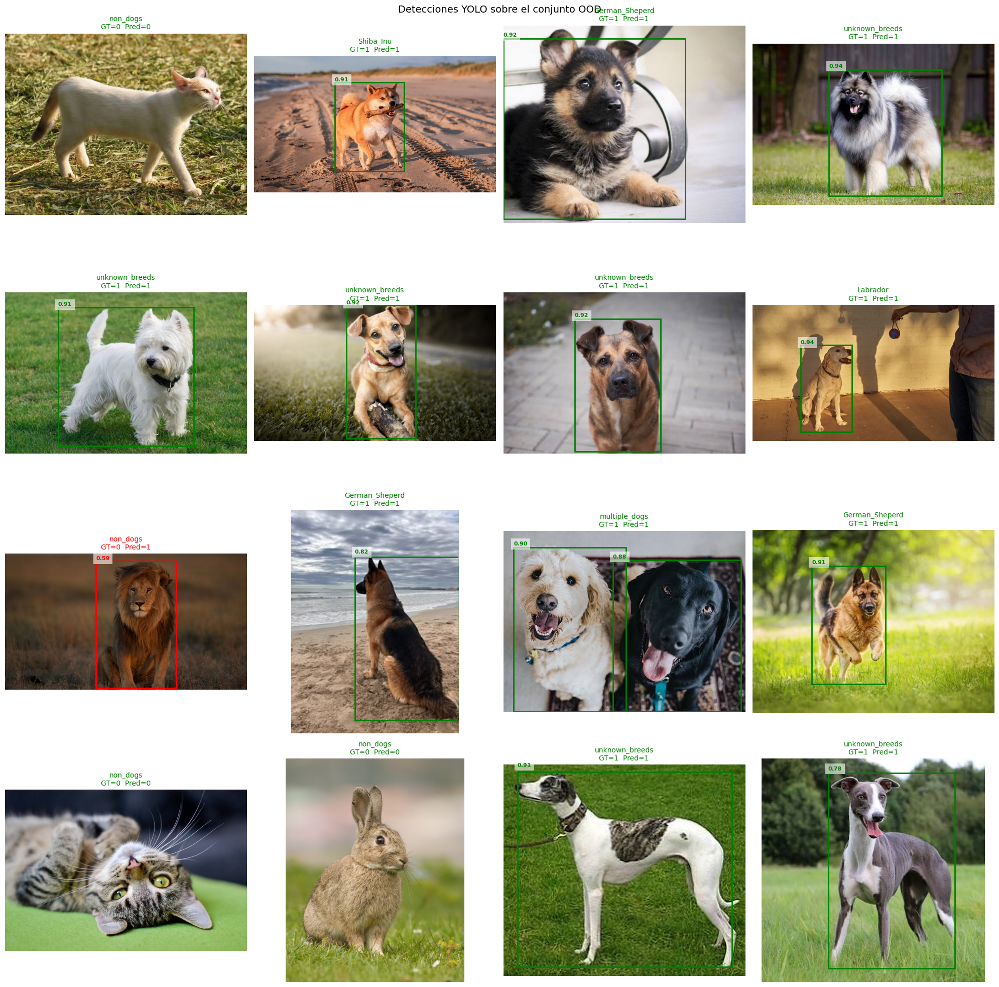

In [16]:
N_SAMPLES = 16
COLS = 4

indices = random.sample(range(len(X_ood_paths)), k=min(N_SAMPLES, len(X_ood_paths)))

rows = (len(indices) + COLS - 1) // COLS
fig, axes = plt.subplots(rows, COLS, figsize=(5 * COLS, 5 * rows))
axes = axes.flatten()

for ax, idx in zip(axes, indices):
    img_path = X_ood_paths[idx]
    label    = y_ood_label[idx]
    gt       = y_ood_yolo[idx]

    image = Image.open(img_path).convert("RGB")
    boxes = detect_dogs(image)
    pred  = int(len(boxes) > 0)
    color = "green" if pred == gt else "red"

    ax.imshow(image)
    ax.set_title(f"{label}\nGT={gt}  Pred={pred}", color=color, fontsize=10)
    ax.axis("off")

    for (x1, y1, x2, y2, score) in boxes:
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 5, f"{score:.2f}",
            color=color, fontsize=8, weight="bold",
            bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
        )

for ax in axes[len(indices):]:
    ax.axis("off")

plt.suptitle("Detecciones YOLO sobre el conjunto OOD", fontsize=14)
plt.tight_layout()
plt.show()

La inspección visual muestra que YOLO logra detectar correctamente perros en la mayoría de las imágenes donde efectivamente están presentes y, al mismo tiempo, evita generar detecciones en gran parte de las imágenes que no contienen perros. Esto sugiere que el detector generaliza adecuadamente sobre escenas reales obtenidas de internet, incluso cuando existen variaciones importantes de fondo, iluminación o composición.

El principal error observable en esta muestra corresponde a un caso donde un león es detectado como perro. Este comportamiento es razonable desde el punto de vista visual, ya que ambas categorías comparten características morfológicas similares y el detector fue entrenado para maximizar capacidad de generalización sobre objetos presentes en COCO, no para discriminar especies visualmente cercanas fuera de su conjunto de entrenamiento.

En términos generales, el análisis cualitativo indica que la etapa de detección funciona correctamente sobre la mayoría de los escenarios representados en el conjunto OOD.

### 6.2 Selección del umbral de confianza óptimo

El umbral de confianza controla cuánta evidencia requiere YOLO antes de aceptar una detección.

Valores bajos tienden a aumentar el recall, ya que se aceptan más detecciones, pero también incrementan el riesgo de falsos positivos. Por el contrario, valores altos suelen reducir falsas alarmas a costa de perder detecciones válidas.

En lugar de fijar este parámetro manualmente, se realiza una búsqueda en grilla evaluando múltiples valores entre 0.05 y 0.95.

La calibración se realiza sobre el conjunto OOD y no sobre Test por dos motivos:

1. El conjunto OOD contiene los cuatro escenarios relevantes de la consigna (known breeds, unknown breeds, multiple dogs y non dogs).
2. Permite reservar el conjunto Test exclusivamente para evaluación posterior, evitando ajustar hiperparámetros sobre el mismo conjunto utilizado para reportar resultados.

La métrica utilizada para seleccionar el mejor valor es el **F1-score**, ya que equilibra simultáneamente precisión y recall en la tarea binaria de detección.

Mejor umbral (conf) : 0.25
Accuracy            : 0.8795
Precision           : 0.9298
Recall              : 0.8983
F1-score            : 0.9138


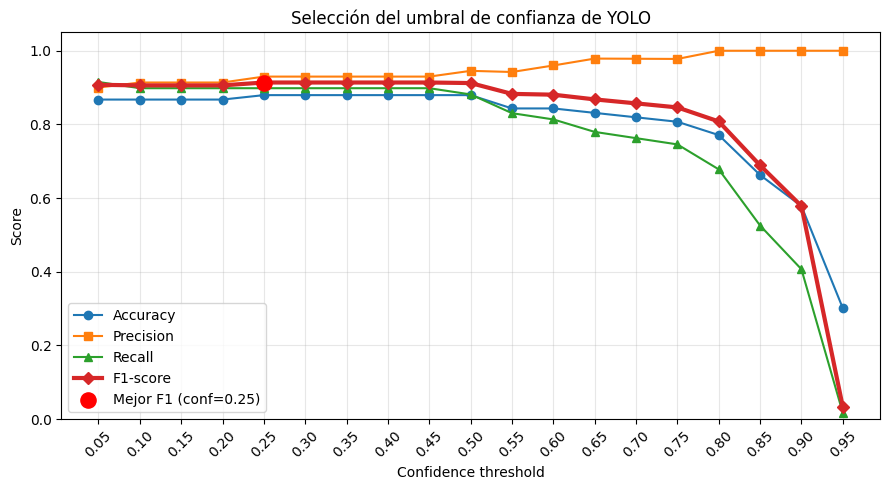

In [17]:
thresholds = np.arange(0.05, 1.00, 0.05)
y_true     = np.array(y_ood_yolo)

accuracies, precisions, recalls, f1_scores = [], [], [], []

for thr in thresholds:
    preds = []
    for img_path in X_ood_paths:
        image = Image.open(img_path).convert("RGB")
        boxes = detect_dogs(image, conf=thr)
        preds.append(int(len(boxes) > 0))
    preds = np.array(preds)
    accuracies.append(accuracy_score(y_true, preds))
    precisions.append(precision_score(y_true, preds, zero_division=0))
    recalls.append(recall_score(y_true, preds, zero_division=0))
    f1_scores.append(f1_score(y_true, preds, zero_division=0))

best_idx = np.argmax(f1_scores)
best_thr = thresholds[best_idx]

print(f"Mejor umbral (conf) : {best_thr:.2f}")
print(f"Accuracy            : {accuracies[best_idx]:.4f}")
print(f"Precision           : {precisions[best_idx]:.4f}")
print(f"Recall              : {recalls[best_idx]:.4f}")
print(f"F1-score            : {f1_scores[best_idx]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(thresholds, accuracies, marker="o",  label="Accuracy")
plt.plot(thresholds, precisions, marker="s",  label="Precision")
plt.plot(thresholds, recalls,    marker="^",  label="Recall")
plt.plot(thresholds, f1_scores,  marker="D",  linewidth=3, label="F1-score")
plt.scatter(best_thr, f1_scores[best_idx], color="red", s=120, zorder=5,
            label=f"Mejor F1 (conf={best_thr:.2f})")
plt.xlabel("Confidence threshold")
plt.ylabel("Score")
plt.title("Selección del umbral de confianza de YOLO")
plt.xticks(thresholds, rotation=45)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Los resultados muestran que el mejor desempeño global se obtiene con un umbral de confianza de **0.25**, alcanzando un F1-score de **0.9138**.

Este valor representa un equilibrio adecuado entre precisión (**0.9298**) y recall (**0.8983**), indicando que el detector logra identificar correctamente la mayoría de las imágenes que contienen perros sin introducir una cantidad excesiva de falsos positivos.

Por este motivo, `conf=0.25` se adopta como configuración por defecto para el resto de las evaluaciones del pipeline.

La selección basada en F1-score resulta especialmente apropiada en este contexto porque tanto las detecciones perdidas como las detecciones espurias impactan negativamente sobre el sistema completo: una detección ausente impide realizar clasificación, mientras que una detección incorrecta puede generar una predicción de raza sobre un objeto que no corresponde a un perro.


## 7. `classify_detected_dog(crop, model, idx_to_class, device)` — Clasificación de Raza

Una vez detectado un perro, el siguiente paso consiste en determinar su raza utilizando alguno de los clasificadores entrenados durante la Etapa 2.

La función `classify_detected_dog` constituye la interfaz unificada de clasificación utilizada por todo el pipeline. Su responsabilidad es recibir un recorte generado por la etapa de detección, aplicar el preprocesamiento apropiado e inferir la raza más probable utilizando el modelo especificado.

A diferencia de la etapa anterior, donde el foco estaba puesto en la localización de objetos, aquí se evalúa la capacidad de distinguir entre las 70 razas presentes en el conjunto de entrenamiento.

### Diseño de la función

La función recibe un recorte de imagen correspondiente a un perro detectado y devuelve una tupla:

```text
(raza_predicha, score_de_confianza)
```

Una decisión de diseño importante es que tanto el modelo como el mapeo de clases se reciben como parámetros explícitos.

La versión inicial del prototipo utilizaba variables globales (`model`, `idx_to_class` y `device`), lo que generaba un fuerte acoplamiento con el estado interno de la notebook. En esta implementación dichos elementos se parametrizan para convertir a `classify_detected_dog` en una función completamente independiente del clasificador utilizado.

Esto aporta varias ventajas:

* Permite reutilizar exactamente la misma función con ResNet-18 y CNN Custom.
* Facilita las pruebas unitarias.
* Reduce dependencias implícitas.
* Evita duplicación de código durante las comparaciones experimentales.

Esta decisión resulta especialmente relevante en esta etapa, donde uno de los objetivos principales es comparar distintos clasificadores bajo las mismas condiciones de inferencia.


### Preprocesamiento de entrada

Los clasificadores fueron entrenados utilizando imágenes normalizadas según las estadísticas de ImageNet, por lo que durante inferencia debe reproducirse exactamente el mismo flujo de preprocesamiento.

Las transformaciones aplicadas son:

* Conversión de BGR a RGB.
* Redimensionamiento a **224×224 píxeles**.
* Conversión a tensor.
* Normalización con:

```text
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
```

Estas estadísticas corresponden al conjunto ImageNet y son las utilizadas durante el entrenamiento de ResNet-18. Mantenerlas durante inferencia garantiza consistencia entre entrenamiento y evaluación.


In [18]:
def classify_detected_dog(
    crop: np.ndarray,
    model: torch.nn.Module,
    idx_to_class: dict,
    device: torch.device,
) -> tuple[str, float]:
    """
    Clasifica la raza del recorte de un perro detectado usando el modelo
    entrenado en la Etapa 2 (self.classifier.load_model()).

    El recorte llega en BGR (OpenCV). Retorna (raza, score).
    """
    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])

    img_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    tensor  = transform(img_rgb).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(tensor)
        probs  = torch.softmax(logits, dim=1)
        score, idx = torch.max(probs, dim=1)

    breed = idx_to_class[idx.item()]
    return breed, score.item()

La predicción se realiza en modo evaluación (`eval`) y dentro de un bloque `torch.no_grad()` para desactivar el cálculo de gradientes.

Esta configuración reduce el consumo de memoria y acelera la inferencia, ya que durante esta etapa únicamente interesa obtener predicciones y no actualizar los pesos del modelo.

La salida final corresponde a la clase con mayor probabilidad según la distribución Softmax generada por el clasificador.


## Funciones adicionales

Se definen funciones que serán utilizadas para verificación y validación de los pipelines.

### Visualización cualitativa del clasificador

Antes de analizar métricas agregadas resulta útil inspeccionar ejemplos individuales para comprender qué tipo de errores cometen los modelos.

La siguiente función genera una grilla de imágenes mostrando la etiqueta real y la predicción obtenida por el clasificador.

Es importante destacar que esta visualización evalúa exclusivamente el clasificador, sin utilizar YOLO. Por lo tanto, la imagen completa se envía directamente al modelo, permitiendo analizar su desempeño aislado sin introducir errores provenientes de la etapa de detección.

In [19]:
def plot_predicciones_grid(clf_model, model_name, img_paths, true_labels, n=16, cols=4):
    """
    Muestra una grilla de n imágenes con la predicción del clasificador.
    Verde = correcto, Rojo = error.
    Nota: el clasificador recibe la imagen completa (sin pasar por YOLO),
    ya que esta visualización evalúa el clasificador de forma aislada.
    """
    clf_model.to(DEVICE)
    indices = random.sample(range(len(img_paths)), k=min(n, len(img_paths)))
    rows    = (len(indices) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    axes = axes.flatten()

    for ax, idx in zip(axes, indices):
        image_pil  = Image.open(img_paths[idx]).convert("RGB")
        image_bgr  = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
        true_label = normalizar(true_labels[idx])

        pred_breed, clf_score = classify_detected_dog(image_bgr, clf_model, idx_to_class, DEVICE)
        pred_breed = normalizar(pred_breed)
        color      = "green" if pred_breed == true_label else "red"

        ax.imshow(image_pil)
        ax.set_title(f"GT: {true_label}\nPred: {pred_breed} ({clf_score:.2f})",
                     color=color, fontsize=9)
        ax.axis("off")

    for ax in axes[len(indices):]:
        ax.axis("off")

    plt.suptitle(f"{model_name} — Predicciones sobre Test", fontsize=14)
    plt.tight_layout()
    plt.show()

### Evaluación del clasificador aislado

La siguiente función calcula las predicciones de un clasificador sobre un conjunto completo de imágenes sin pasar previamente por YOLO.

El objetivo es establecer una línea base de referencia para comparar posteriormente contra el pipeline completo.

Esta distinción es fundamental para interpretar correctamente los resultados: cualquier degradación observada más adelante podrá atribuirse a la incorporación de la etapa de detección y no necesariamente a una disminución de la capacidad discriminativa del clasificador.

In [20]:
def evaluar_clasificador(clf_model, model_name, img_paths, true_labels):
    """
    Evalúa el clasificador de forma aislada (sin YOLO) sobre un conjunto de imágenes.
    Retorna (y_true, y_pred) para uso posterior (matriz de confusión, comparaciones).
    """
    clf_model.to(DEVICE)
    y_true, y_pred = [], []

    for img_path, true_label in zip(img_paths, true_labels):
        image_pil = Image.open(img_path).convert("RGB")
        image_bgr = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
        pred_breed, _ = classify_detected_dog(image_bgr, clf_model, idx_to_class, DEVICE)
        y_true.append(normalizar(true_label))
        y_pred.append(normalizar(pred_breed))

    acc = accuracy_score(y_true, y_pred)
    print(f"[{model_name}] Accuracy global (Test): {acc:.4f}\n")
    print(classification_report(y_true, y_pred, zero_division=0))

    return y_true, y_pred

### Matriz de confusión

Las métricas globales permiten resumir el rendimiento del modelo, pero no muestran qué razas tienden a confundirse entre sí.

La matriz de confusión complementa este análisis visualizando las clases más frecuentes del conjunto evaluado y mostrando cómo se distribuyen los errores de clasificación.

Para mejorar la legibilidad se restringe la visualización a las razas con mayor cantidad de ejemplos, evitando matrices excesivamente grandes debido a las 70 clases presentes en el problema.

In [21]:
def plot_confusion_matrix(y_true, y_pred, model_name, n_top=10):
    """
    Grafica la matriz de confusión sobre las n_top clases más frecuentes.
    """
    top_classes = [c for c, _ in Counter(y_true).most_common(n_top)]
    mask  = [l in top_classes for l in y_true]
    y_t   = [l for l, m in zip(y_true, mask) if m]
    y_p   = [l for l, m in zip(y_pred, mask) if m]
    cm    = confusion_matrix(y_t, y_p, labels=top_classes)

    fig, ax = plt.subplots(figsize=(12, 10))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=top_classes).plot(
        ax=ax, cmap=plt.cm.Blues, xticks_rotation=45, colorbar=False
    )
    ax.set_title(f"{model_name} — Matriz de confusión (Top {n_top} razas, Test)")
    plt.tight_layout()
    plt.show()

### Visualización paso a paso del pipeline

La siguiente utilidad permite inspeccionar visualmente las distintas etapas del sistema completo:

1. Imagen original.
2. Detecciones producidas por YOLO.
3. Clasificación final obtenida sobre cada recorte.

Este tipo de visualización resulta especialmente útil para identificar si un error proviene de la etapa de detección o de la etapa de clasificación, facilitando el análisis cualitativo del pipeline completo.

In [22]:
def draw_pipeline_row(axes_row, img_path, true_label, clf_gt, clf_model, model_name=""):
    """
    Dibuja una fila de 3 columnas: original | YOLO | predicción final.
    """
    image_pil = Image.open(img_path).convert("RGB")
    image_bgr = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
    boxes     = detect_dogs(image_pil)

    # Col 0: original
    axes_row[0].imshow(image_pil)
    axes_row[0].set_title(f"GT: {true_label}\n(clf_gt: {clf_gt})", fontsize=10)
    axes_row[0].axis("off")

    # Col 1: YOLO
    axes_row[1].imshow(image_pil)
    axes_row[1].set_title(f"YOLO — {len(boxes)} perro/s", fontsize=10)
    axes_row[1].axis("off")
    for (x1, y1, x2, y2, det_score) in boxes:
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="blue", facecolor="none"
        )
        axes_row[1].add_patch(rect)
        axes_row[1].text(
            x1, y1 - 5, f"dog:{det_score:.2f}",
            color="blue", fontsize=8, weight="bold",
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
        )

    # Col 2: predicción final
    title = f"Predicción final\n({model_name})" if model_name else "Predicción final"
    axes_row[2].imshow(image_pil)
    axes_row[2].axis("off")
    if not boxes:
        axes_row[2].set_title("Sin detecciones", color="gray", fontsize=10)
    else:
        axes_row[2].set_title(title, fontsize=10)

    for (x1, y1, x2, y2, det_score) in boxes:
        crop       = image_bgr[y1:y2, x1:x2]
        pred_breed, clf_score = classify_detected_dog(crop, clf_model, idx_to_class, DEVICE)
        pred_breed = normalizar(pred_breed)

        if clf_gt == "known":
            color = "green" if pred_breed == normalizar(true_label) else "red"
        else:
            color = "orange"   # sin GT de clasificación

        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        axes_row[2].add_patch(rect)
        axes_row[2].text(
            x1, y1 - 5,
            f"{pred_breed}\ndet:{det_score:.2f}  clf:{clf_score:.2f}",
            color=color, fontsize=8, weight="bold", va="bottom",
            bbox=dict(facecolor="white", alpha=0.7, edgecolor=color, linewidth=1)
        )

### Selección de ejemplos de referencia

Se seleccionan imágenes representativas que serán reutilizadas en distintas visualizaciones del notebook.

Mantener ejemplos fijos permite comparar de forma consistente el comportamiento de ambos clasificadores y facilita la interpretación de las diferencias observadas a lo largo de las distintas secciones.

In [23]:
N_TEST = 4
N_OOD  = 4

test_indices = random.sample(range(len(X_test_paths)), k=min(N_TEST, len(X_test_paths)))
ood_indices  = random.sample(range(len(X_ood_paths)),  k=min(N_OOD,  len(X_ood_paths)))

FIXED_TEST_INDICES = test_indices
FIXED_OOD_INDICES  = ood_indices


# Imágenes fijas para los 3 casos
_img_single      = X_test_paths[0]
_true_single     = y_test_labels[0]

_multi_indices   = [i for i, l in enumerate(y_ood_label) if l == "multiple_dogs"]
_img_multi       = X_ood_paths[random.choice(_multi_indices)] if _multi_indices else None

_non_dog_indices = [i for i, g in enumerate(y_ood_yolo) if g == 0]
_idx_non_dog     = random.choice(_non_dog_indices) if _non_dog_indices else None
_img_non_dog     = X_ood_paths[_idx_non_dog] if _idx_non_dog is not None else None
_label_non_dog   = y_ood_label[_idx_non_dog] if _idx_non_dog is not None else ""

### Casos requeridos por la consigna

La consigna solicita verificar explícitamente que el sistema sea capaz de operar en tres escenarios distintos:

* Un único perro en escena.
* Múltiples perros simultáneamente.
* Escenas sin perros.

La siguiente función genera una visualización específica para estos tres casos, mostrando simultáneamente las detecciones de YOLO y las predicciones de raza obtenidas por el clasificador.

Este análisis permite validar visualmente el comportamiento esperado del pipeline más allá de las métricas agregadas.

In [24]:
COLORS_MULTI = ["cyan", "yellow", "magenta", "lime", "orange"]

def plot_casos_pipeline(clf_model, model_name, img_single, true_label_single,
                        img_multi, img_non_dog, label_non_dog):
    """
    Muestra los 3 casos requeridos por la consigna en una única figura de 3 columnas.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(f"Casos del pipeline [{model_name}]  |  Verde=correcto  Rojo=error", fontsize=13)

    # ── Caso 1: un único perro ─────────────────────────────────────────────
    ax = axes[0]
    image_pil = Image.open(img_single).convert("RGB")
    image_bgr = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
    boxes     = detect_dogs(image_pil)
    true_norm = normalizar(true_label_single)

    ax.imshow(image_pil)
    ax.axis("off")
    if not boxes:
        ax.set_title(f"Caso 1 — Un perro\nGT: {true_norm}\n⚠ Sin detección YOLO", fontsize=10, color="red")
    else:
        for x1, y1, x2, y2, det_score in boxes:
            crop        = image_bgr[y1:y2, x1:x2]
            breed, clf_score = classify_detected_dog(crop, clf_model, idx_to_class, DEVICE)
            breed       = normalizar(breed)
            color       = "green" if breed == true_norm else "red"
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=color, facecolor="none"
            ))
            ax.text(x1, y1-5, f"{breed}\ndet:{det_score:.2f}  clf:{clf_score:.2f}",
                    color=color, fontsize=9, weight="bold", va="bottom",
                    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none"))
        ax.set_title(f"Caso 1 — Un perro\nGT: {true_norm}", fontsize=10)

    # ── Caso 2: múltiples perros ───────────────────────────────────────────
    ax = axes[1]
    if img_multi is None:
        ax.set_title("Caso 2 — Múltiples perros\n⚠ Sin imagen disponible", fontsize=10, color="gray")
        ax.axis("off")
    else:
        image_pil = Image.open(img_multi).convert("RGB")
        image_bgr = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
        boxes     = detect_dogs(image_pil)

        ax.imshow(image_pil)
        ax.axis("off")
        for i, (x1, y1, x2, y2, det_score) in enumerate(boxes):
            color = COLORS_MULTI[i % len(COLORS_MULTI)]
            crop  = image_bgr[y1:y2, x1:x2]
            breed, clf_score = classify_detected_dog(crop, clf_model, idx_to_class, DEVICE)
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=color, facecolor="none"
            ))
            ax.text(x1, y1-5,
                    f"[{i+1}] {normalizar(breed)}\ndet:{det_score:.2f}  clf:{clf_score:.2f}",
                    color=color, fontsize=9, weight="bold", va="bottom",
                    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none"))
        ax.set_title(f"Caso 2 — Múltiples perros\n{len(boxes)} detectado/s", fontsize=10)

    # ── Caso 3: escena sin perros ──────────────────────────────────────────
    ax = axes[2]
    if img_non_dog is None:
        ax.set_title("Caso 3 — Sin perros\n⚠ Sin imagen disponible", fontsize=10, color="gray")
        ax.axis("off")
    else:
        image_pil = Image.open(img_non_dog).convert("RGB")
        boxes     = detect_dogs(image_pil)

        ax.imshow(image_pil)
        ax.axis("off")
        for x1, y1, x2, y2, det_score in boxes:
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor="red", facecolor="none"
            ))
            ax.text(x1, y1-5, f"FP: dog {det_score:.2f}", color="red", fontsize=9, weight="bold",
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))
        resultado = "Correcto (0 detecciones)" if not boxes else f"Falso positivo ({len(boxes)} detección/es)"
        ax.set_title(f"Caso 3 — Escena sin perros\n{label_non_dog}\n{resultado}", fontsize=10)

    plt.tight_layout()
    plt.show()

### Evaluación del pipeline completo

A diferencia de la evaluación realizada anteriormente sobre los clasificadores aislados, esta función evalúa el sistema completo:

```text
Imagen → YOLO → Recorte → Clasificador
```

La métrica resultante refleja el comportamiento real de producción, donde una predicción correcta depende simultáneamente de que:

1. YOLO detecte correctamente al perro.
2. El recorte generado sea adecuado.
3. El clasificador prediga la raza correcta.

Una decisión importante es que las imágenes sin detección se registran utilizando la etiqueta especial:

```text
__no_detection__
```

Esta predicción nunca coincide con ninguna raza real y por lo tanto se contabiliza como error.

Aunque esta decisión penaliza las métricas finales, representa fielmente el comportamiento del sistema real: si el detector falla, el usuario tampoco recibe una clasificación válida.

In [25]:
def evaluar_pipeline(img_paths, true_labels, clf_gt_list=None):
    """
    Evalúa el pipeline completo (YOLO + ambos clasificadores) sobre un conjunto de imágenes.
    Retorna (y_true_resnet, y_pred_resnet, y_true_cnn, y_pred_cnn, n_sin_deteccion).
    clf_gt_list: si es None, asume que todas las imágenes tienen ground truth conocido.
    """
    y_true_r, y_pred_r = [], []
    y_true_c, y_pred_c = [], []
    n_sin_det = 0

    for i, (img_path, true_label) in enumerate(zip(img_paths, true_labels)):
        image_pil = Image.open(img_path).convert("RGB")
        image_bgr = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
        boxes     = detect_dogs(image_pil)
        true_norm = normalizar(true_label)

        if not boxes:
            n_sin_det += 1
            y_true_r.append(true_norm); y_pred_r.append("__no_detection__")
            y_true_c.append(true_norm); y_pred_c.append("__no_detection__")
            continue

        best_box           = max(boxes, key=lambda b: b[4])
        x1, y1, x2, y2, _ = best_box
        crop               = image_bgr[y1:y2, x1:x2]

        pred_r, _ = classify_detected_dog(crop, modelo_resnet, idx_to_class, DEVICE)
        pred_c, _ = classify_detected_dog(crop, modelo_cnn,    idx_to_class, DEVICE)

        y_true_r.append(true_norm); y_pred_r.append(normalizar(pred_r))
        y_true_c.append(true_norm); y_pred_c.append(normalizar(pred_c))

    return y_true_r, y_pred_r, y_true_c, y_pred_c, n_sin_det

### Métricas de evaluación

Para comparar clasificadores y configuraciones del pipeline se utilizan cuatro métricas complementarias:

* Accuracy.
* Precision macro.
* Recall macro.
* F1-score macro.

Las variantes macro resultan especialmente apropiadas en problemas multiclase porque asignan el mismo peso a cada raza independientemente de su frecuencia dentro del conjunto evaluado.


In [26]:
def metricas(y_true, y_pred):
    return {
        "acc":  accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "rec":  recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1":   f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

### Comparación visual entre clasificadores

La siguiente visualización permite comparar directamente el comportamiento de ResNet-18 y CNN Custom sobre las mismas imágenes.

Cada fila muestra:

* Detecciones realizadas por YOLO.
* Predicción final utilizando ResNet-18.
* Predicción final utilizando CNN Custom.

Este formato facilita identificar diferencias cualitativas entre ambos modelos y observar cómo una misma detección puede conducir a clasificaciones distintas dependiendo de la arquitectura utilizada.

In [27]:
def plot_comparacion_pipeline(img_paths, true_labels, titulo, n=6):
    """
    Muestra n imágenes del conjunto dado con 3 columnas:
    Col 0: imagen + box YOLO | Col 1: predicción ResNet-18 | Col 2: predicción CNN Custom
    """
    indices = random.sample(range(len(img_paths)), k=min(n, len(img_paths)))

    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))

    for row, idx in enumerate(indices):
        img_path   = img_paths[idx]
        true_label = normalizar(true_labels[idx])
        image_pil  = Image.open(img_path).convert("RGB")
        image_bgr  = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
        boxes      = detect_dogs(image_pil)

        # Col 0: YOLO
        axes[row][0].imshow(image_pil)
        axes[row][0].set_title(f"GT: {true_label}\nYOLO: {len(boxes)} detección/es", fontsize=10)
        axes[row][0].axis("off")
        for (x1, y1, x2, y2, det_score) in boxes:
            axes[row][0].add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor="blue", facecolor="none"
            ))
            axes[row][0].text(x1, y1-5, f"dog:{det_score:.2f}", color="blue", fontsize=8,
                              weight="bold", bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))

        if not boxes:
            for col in [1, 2]:
                axes[row][col].imshow(image_pil)
                axes[row][col].set_title("Sin detección YOLO", color="gray", fontsize=10)
                axes[row][col].axis("off")
            continue

        best_box           = max(boxes, key=lambda b: b[4])
        x1, y1, x2, y2, det_score = best_box
        crop = image_bgr[y1:y2, x1:x2]

        pred_resnet, score_resnet = classify_detected_dog(crop, modelo_resnet, idx_to_class, DEVICE)
        pred_cnn,    score_cnn    = classify_detected_dog(crop, modelo_cnn,    idx_to_class, DEVICE)
        pred_resnet = normalizar(pred_resnet)
        pred_cnn    = normalizar(pred_cnn)
        col_resnet  = "green" if pred_resnet == true_label else "red"
        col_cnn     = "green" if pred_cnn    == true_label else "red"

        for col_idx, (pred, score, color, model_name) in enumerate([
            (pred_resnet, score_resnet, col_resnet, "ResNet-18"),
            (pred_cnn,    score_cnn,    col_cnn,    "CNN Custom"),
        ], start=1):
            axes[row][col_idx].imshow(image_pil)
            axes[row][col_idx].add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=color, facecolor="none"
            ))
            axes[row][col_idx].text(
                x1, y1-5, f"{pred}\ndet:{det_score:.2f}  clf:{score:.2f}",
                color=color, fontsize=8, weight="bold", va="bottom",
                bbox=dict(facecolor="white", alpha=0.7, edgecolor=color, linewidth=1)
            )
            axes[row][col_idx].set_title(f"{model_name}\n{pred} ({score:.2f})", color=color, fontsize=10)
            axes[row][col_idx].axis("off")

    plt.suptitle(
        f"{titulo}\nCol 1: YOLO  |  Col 2: ResNet-18  |  Col 3: CNN Custom  |  Verde=correcto  Rojo=error",
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

## 8. Pipeline con ResNet-18 Fine-Tuned

En esta sección se analiza el desempeño de **ResNet-18 Fine-Tuned**, el modelo que obtuvo los mejores resultados durante la Etapa 2.

Primero se evalúa el clasificador de forma aislada sobre el conjunto Test para verificar que conserva el rendimiento observado durante el entrenamiento. Posteriormente se analiza su comportamiento integrado dentro del pipeline completo junto a YOLO.

Esta separación resulta fundamental para distinguir qué errores provienen del clasificador y cuáles son introducidos por la etapa de detección.

### 8.1 Visualización cualitativa sobre Test

Antes de analizar métricas agregadas resulta útil inspeccionar ejemplos individuales del conjunto Test.

En esta visualización el clasificador recibe directamente las imágenes, sin pasar previamente por YOLO. Por lo tanto, el objetivo es evaluar exclusivamente la capacidad de clasificación de ResNet-18, sin introducir posibles errores provenientes de la etapa de detección.

Las predicciones correctas se muestran en verde y los errores en rojo.

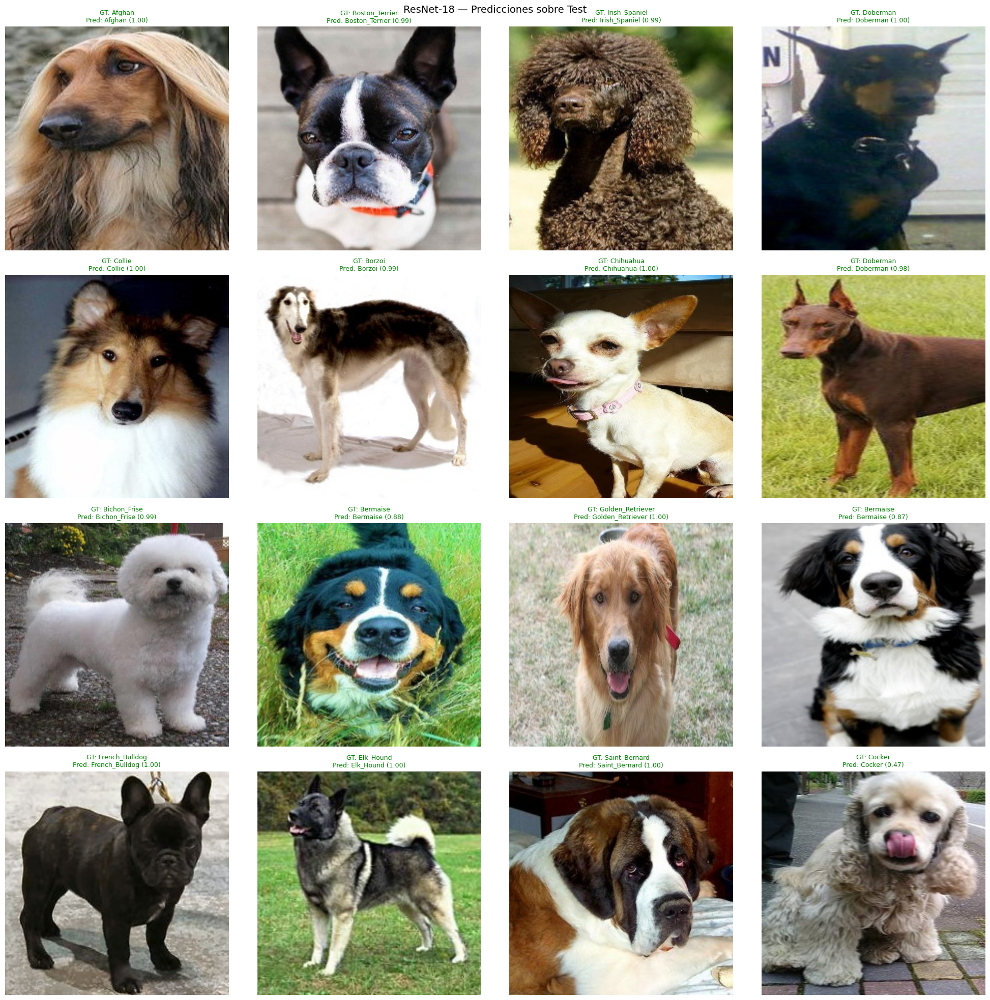

In [28]:
plot_predicciones_grid(modelo_resnet, "ResNet-18", X_test_paths, y_test_labels)

En la muestra visualizada, ResNet-18 clasifica correctamente todas las imágenes seleccionadas del conjunto Test.

Aunque esta visualización corresponde únicamente a una pequeña muestra aleatoria y no reemplaza una evaluación cuantitativa completa, permite comprobar cualitativamente que el modelo reconoce correctamente distintas razas y resulta consistente con el elevado desempeño observado durante la Etapa 2.

### 8.2 Métricas cuantitativas sobre Test

A diferencia de la visualización anterior, esta evaluación considera las 700 imágenes del conjunto Test.

Es importante destacar que estas métricas corresponden exclusivamente al clasificador aislado. Las imágenes se clasifican directamente, sin utilizar la etapa de detección con YOLO.

Por este motivo, los valores obtenidos representan una referencia del rendimiento de ResNet-18 cuando recibe las imágenes sin introducir los posibles errores asociados al proceso de detección y recorte.

In [29]:
y_true_resnet, y_pred_resnet = evaluar_clasificador(modelo_resnet, "ResNet-18", X_test_paths, y_test_labels)

[ResNet-18] Accuracy global (Test): 0.9700

                   precision    recall  f1-score   support

           Afghan       1.00      1.00      1.00        10
 African_Wild_Dog       1.00      1.00      1.00        10
         Airedale       1.00      1.00      1.00        10
American_Hairless       1.00      1.00      1.00        10
 American_Spaniel       0.88      0.70      0.78        10
          Basenji       0.91      1.00      0.95        10
           Basset       1.00      1.00      1.00        10
           Beagle       1.00      1.00      1.00        10
   Bearded_Collie       1.00      1.00      1.00        10
         Bermaise       1.00      1.00      1.00        10
     Bichon_Frise       1.00      1.00      1.00        10
         Blenheim       0.91      1.00      0.95        10
       Bloodhound       1.00      1.00      1.00        10
         Bluetick       1.00      1.00      1.00        10
    Border_Collie       0.91      1.00      0.95        10
           

ResNet-18 alcanza una **accuracy global de 97.00 %**, confirmando el excelente desempeño observado durante la Etapa 2.

Las métricas macro promedio también presentan valores cercanos al 97 % para Precision, Recall y F1-score. Esto indica que el modelo mantiene un comportamiento equilibrado entre las distintas razas, sin concentrar su rendimiento únicamente en unas pocas clases.

La mayoría de las clases presenta valores elevados de precisión y sensibilidad, aunque existen algunas excepciones donde aparecen errores puntuales de clasificación. Estas dificultades se concentran principalmente en determinadas razas visualmente similares.

En conjunto, estos resultados validan que ResNet-18 constituye una base sólida para la construcción del pipeline completo y establecen una referencia que será utilizada posteriormente para analizar el impacto de la etapa de detección.

### 8.3 Matriz de confusión — ResNet-18 (Top 10 razas)

La matriz de confusión permite analizar con mayor detalle el comportamiento del modelo sobre las clases seleccionadas del conjunto Test.

Mientras que las métricas globales resumen el rendimiento total, esta visualización muestra explícitamente qué razas son clasificadas correctamente y cuáles presentan confusiones con otras categorías.

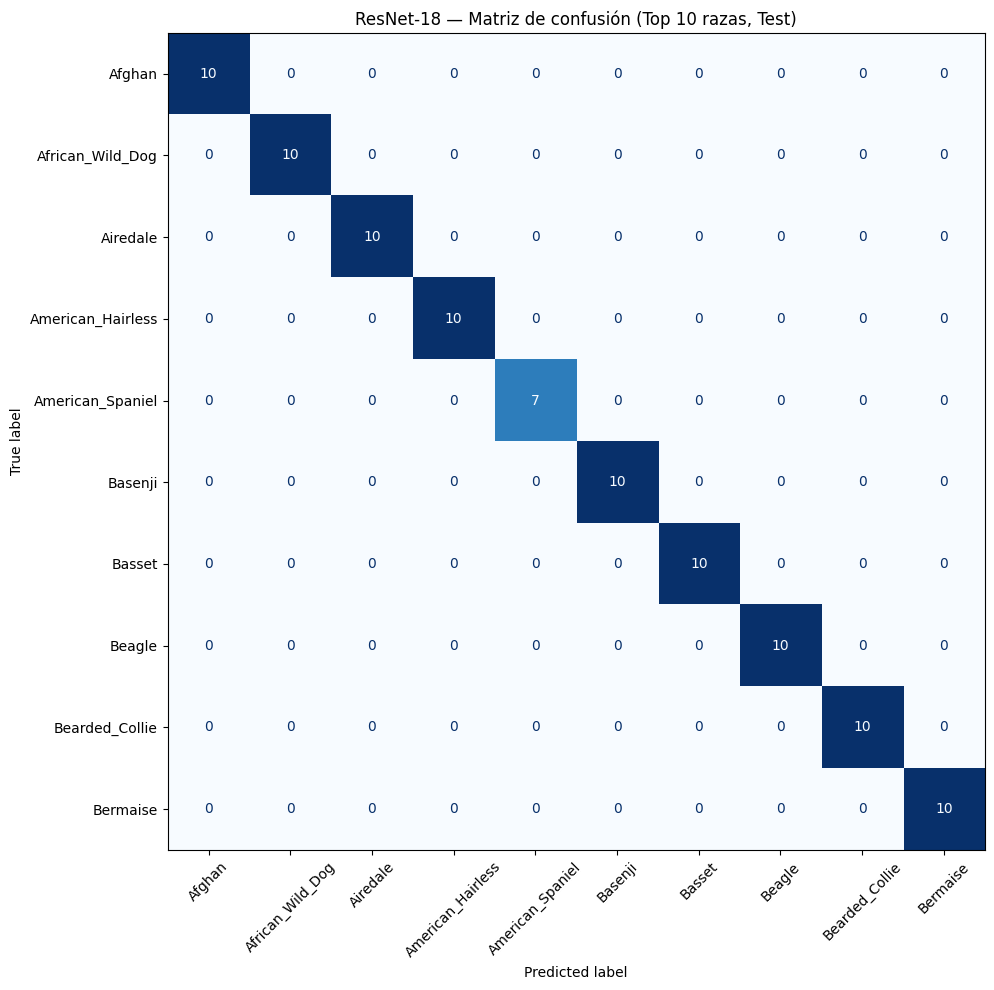

In [30]:
plot_confusion_matrix(y_true_resnet, y_pred_resnet, "ResNet-18")

La matriz presenta una diagonal principal claramente dominante, lo que indica que la mayoría de las imágenes son clasificadas correctamente.

Sin embargo, también pueden observarse errores puntuales en determinadas clases. Esto coincide con los resultados del reporte de clasificación, donde algunas razas presentan un Recall inferior al 100 %, como American Spaniel y Bulldog.

Estas diferencias reflejan que, aunque el modelo consigue un desempeño general muy elevado, todavía existen casos particulares en los que determinadas características visuales dificultan la diferenciación entre razas.

El análisis de la matriz permite identificar estas confusiones y complementar las métricas globales con información más específica sobre el comportamiento del clasificador.

### 8.4 Pipeline visual completo (Test + OOD)

La siguiente visualización muestra el flujo completo del sistema:

Imagen → YOLO → Recorte → ResNet-18

Para cada ejemplo se presentan tres etapas:

1. Imagen original.
2. Detecciones realizadas por YOLO.
3. Predicción final obtenida por ResNet-18.

Los colores utilizados permiten distinguir los distintos resultados:

- Verde: predicción correcta.
- Rojo: predicción incorrecta.
- Naranja: no existe ground truth de clasificación disponible.

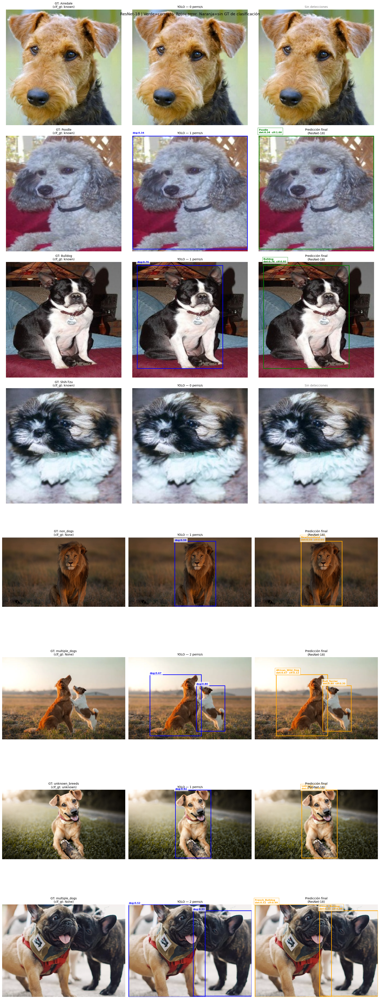

In [31]:
N_ROWS = N_TEST + N_OOD
fig, axes = plt.subplots(N_ROWS, 3, figsize=(18, 6 * N_ROWS))

for row, idx in enumerate(test_indices):
    draw_pipeline_row(axes[row], X_test_paths[idx], y_test_labels[idx],
                      clf_gt="known", clf_model=modelo_resnet, model_name="ResNet-18")
    axes[row][0].set_ylabel("TEST", fontsize=11, fontweight="bold", labelpad=10)

for row, idx in enumerate(ood_indices):
    abs_row = N_TEST + row
    draw_pipeline_row(axes[abs_row], X_ood_paths[idx], y_ood_label[idx],
                      clf_gt=y_ood_clf[idx], clf_model=modelo_resnet, model_name="ResNet-18")
    axes[abs_row][0].set_ylabel("OOD", fontsize=11, fontweight="bold", labelpad=10)

plt.suptitle(
    "ResNet-18 | Verde=correcto  Rojo=error  Naranja=sin GT de clasificación",
    fontsize=13
)
plt.tight_layout()
plt.show()

La visualización permite observar que el rendimiento final del sistema depende simultáneamente de la calidad de las detecciones producidas por YOLO y de la capacidad de clasificación de ResNet-18.

En los ejemplos donde YOLO localiza correctamente al perro y genera un recorte adecuado, el clasificador puede analizar las características visuales del animal para determinar su raza. Sin embargo, una detección ausente o un recorte imperfecto puede impedir que la etapa de clasificación produzca un resultado correcto.

Los ejemplos OOD permiten analizar el comportamiento del pipeline frente a imágenes que presentan condiciones diferentes a las del conjunto de entrenamiento, incluyendo animales de otras especies, múltiples sujetos y escenas con oclusiones.

Entre los casos observados se destacan:

- **Detecciones ausentes:** algunas imágenes no presentan una predicción final, lo que puede estar relacionado con la ausencia de detecciones válidas o con el incumplimiento de los umbrales de confianza configurados.
- **Escenas OOD:** la presencia de animales de otras especies, como un león, permite estudiar el comportamiento del sistema frente a imágenes que no pertenecen a las 70 clases caninas.
- **Múltiples sujetos:** las imágenes con varios perros permiten analizar cómo responde el pipeline cuando debe procesar distintas detecciones dentro de una misma escena.
- **Oclusiones y elementos externos:** objetos que interfieren con la apariencia del animal pueden dificultar tanto la detección como la clasificación.

En conjunto, esta visualización permite identificar limitaciones que no aparecen al evaluar únicamente el clasificador de manera aislada y demuestra la importancia de analizar todas las etapas del pipeline de forma integrada.

### 8.5 Casos específicos requeridos por la consigna — ResNet-18

La consigna establece explícitamente que el sistema debe ser capaz de operar en tres escenarios diferentes:

1. Un único perro en escena.
2. Múltiples perros simultáneamente.
3. Escenas sin perros.

La siguiente visualización permite verificar visualmente el comportamiento del pipeline completo frente a cada uno de estos casos.

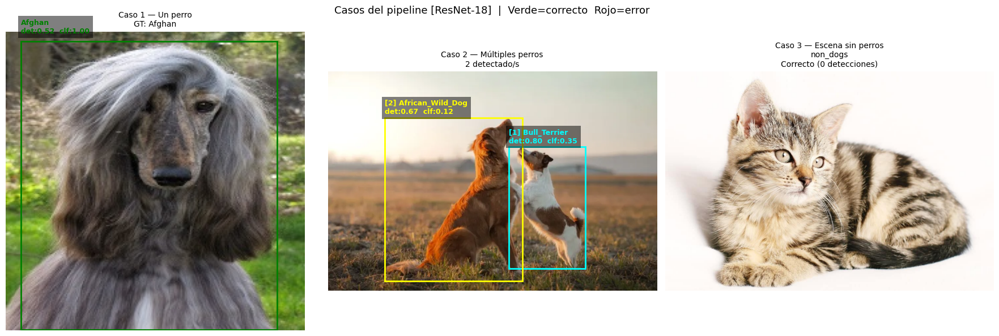

In [32]:
plot_casos_pipeline(modelo_resnet, "ResNet-18",
                    _img_single, _true_single,
                    _img_multi, _img_non_dog, _label_non_dog)

**Caso 1: un único perro**

En la primera imagen se observa un Lebrel Afgano. YOLO localiza correctamente al animal mediante una bounding box y ResNet-18 predice la raza esperada con una elevada confianza de clasificación. El resultado es correcto, demostrando el funcionamiento adecuado de ambas etapas para una escena con un único perro.

**Caso 2: múltiples perros**

En la segunda imagen se presenta una escena con dos perros interactuando. YOLO consigue detectar ambos sujetos y generar dos regiones de interés independientes.

Posteriormente, ResNet-18 procesa cada recorte y produce una predicción de raza para cada uno. Este escenario permite comprobar que el pipeline puede gestionar múltiples detecciones dentro de una misma imagen, aunque la calidad de las clasificaciones depende de las características visuales de cada recorte y de las posibles oclusiones entre los animales.

**Caso 3: escena sin perros**

Finalmente, se evalúa una imagen que contiene un gato. El detector no genera detecciones de perros, por lo que el pipeline identifica correctamente la ausencia de objetos pertenecientes a la categoría objetivo.

Este comportamiento constituye un verdadero negativo y resulta especialmente importante para evitar clasificaciones innecesarias sobre objetos que no pertenecen al dominio del sistema.

En conjunto, estos ejemplos permiten verificar el funcionamiento del pipeline frente a los tres escenarios funcionales requeridos por la consigna.

## 9. Pipeline con CNN Custom

En esta sección se repite exactamente el mismo procedimiento de evaluación realizado con ResNet-18, pero utilizando la arquitectura `cnn_custom` desarrollada desde cero durante la Etapa 2.

Para garantizar una comparación justa, se utilizan las mismas imágenes, métricas y visualizaciones presentadas anteriormente.

A diferencia de ResNet-18, este modelo no dispone de pesos pre-entrenados sobre ImageNet. Todo el proceso de aprendizaje se realiza exclusivamente sobre el dataset de entrenamiento del trabajo práctico, por lo que se espera una menor capacidad de generalización y una convergencia más limitada frente a arquitecturas basadas en transferencia de aprendizaje.

El objetivo de esta sección es cuantificar dicha diferencia y analizar cómo impacta sobre el comportamiento del pipeline completo.

### 9.1 Visualización cualitativa sobre Test

Se evalúa nuevamente el clasificador de forma aislada sobre imágenes del conjunto Test, utilizando exactamente las mismas muestras mostradas en la sección anterior.

Esto permite realizar una comparación visual directa entre ResNet-18 y CNN Custom bajo las mismas condiciones de evaluación.

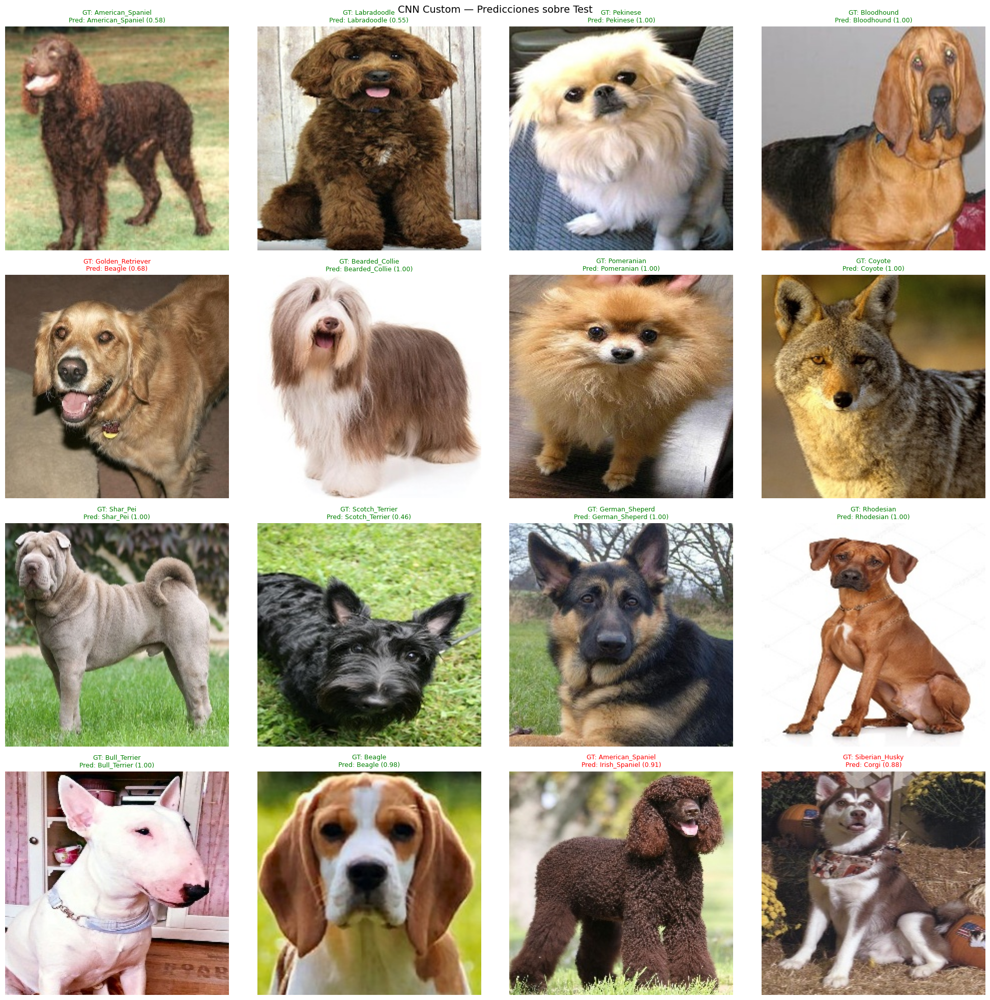

In [33]:
plot_predicciones_grid(modelo_cnn, "CNN Custom", X_test_paths, y_test_labels)

En la muestra visualizada, la CNN Custom clasifica correctamente la mayoría de las imágenes, aunque presenta **3 errores de clasificación**.

A diferencia de lo observado con ResNet-18, que clasificaba correctamente todos los ejemplos seleccionados, la CNN personalizada presenta algunas dificultades para distinguir determinadas razas, incluso cuando recibe las mismas imágenes.

Este comportamiento es consistente con los resultados obtenidos durante la Etapa 2. Al no disponer de pesos preentrenados sobre ImageNet, la red debe aprender todas las características visuales directamente a partir del conjunto de entrenamiento, lo que limita su capacidad de generalización en comparación con el modelo basado en transferencia de aprendizaje.

Si bien el resultado de esta muestra es mayoritariamente satisfactorio, permite observar algunas de las limitaciones que posteriormente se reflejan en las métricas cuantitativas.

### 9.2 Métricas cuantitativas sobre Test

Al igual que en la sección anterior, esta evaluación corresponde exclusivamente al clasificador aislado.

Las imágenes del conjunto Test se envían directamente a la CNN sin utilizar la etapa de detección con YOLO, permitiendo medir únicamente la capacidad de clasificación aprendida por la arquitectura.

In [34]:
y_true_cnn, y_pred_cnn = evaluar_clasificador(modelo_cnn, "CNN Custom", X_test_paths, y_test_labels)

[CNN Custom] Accuracy global (Test): 0.8357

                   precision    recall  f1-score   support

           Afghan       1.00      0.90      0.95        10
 African_Wild_Dog       0.90      0.90      0.90        10
         Airedale       1.00      0.80      0.89        10
American_Hairless       0.75      0.90      0.82        10
 American_Spaniel       1.00      0.80      0.89        10
          Basenji       0.69      0.90      0.78        10
           Basset       0.88      0.70      0.78        10
           Beagle       0.71      1.00      0.83        10
   Bearded_Collie       0.90      0.90      0.90        10
         Bermaise       0.91      1.00      0.95        10
     Bichon_Frise       0.91      1.00      0.95        10
         Blenheim       0.83      1.00      0.91        10
       Bloodhound       0.83      1.00      0.91        10
         Bluetick       0.75      0.90      0.82        10
    Border_Collie       0.83      1.00      0.91        10
          

La CNN Custom alcanza una **accuracy global de 83.57 %**, un resultado considerablemente inferior al 97.00 % obtenido por ResNet-18.

Las métricas macro promedio muestran un comportamiento relativamente equilibrado, con valores de 0.85 para precision, 0.84 para recall y 0.83 para F1-score. Esto indica que, si bien el modelo consigue clasificar correctamente una proporción importante de las imágenes, todavía presenta dificultades para distinguir determinadas razas.

Puede observarse además una variabilidad considerable entre clases. Mientras algunas alcanzan valores elevados de precision y recall, otras presentan un desempeño notablemente inferior. Por ejemplo, Bulldog obtiene un F1-score de 0.40, evidenciando dificultades particulares para reconocer esta raza.

La diferencia respecto de ResNet-18 confirma las ventajas del aprendizaje por transferencia en este problema. Los pesos preentrenados sobre ImageNet proporcionan representaciones visuales que permiten obtener una generalización superior, especialmente cuando se trabaja con un conjunto de datos limitado y un número elevado de clases.

### 9.3 Matriz de confusión — CNN Custom (Top 10 razas)

La matriz de confusión permite visualizar con mayor detalle cómo se distribuyen los errores de clasificación entre las razas más frecuentes del conjunto Test.

Esta representación facilita comparar el patrón de confusiones de CNN Custom con el observado previamente para ResNet-18.

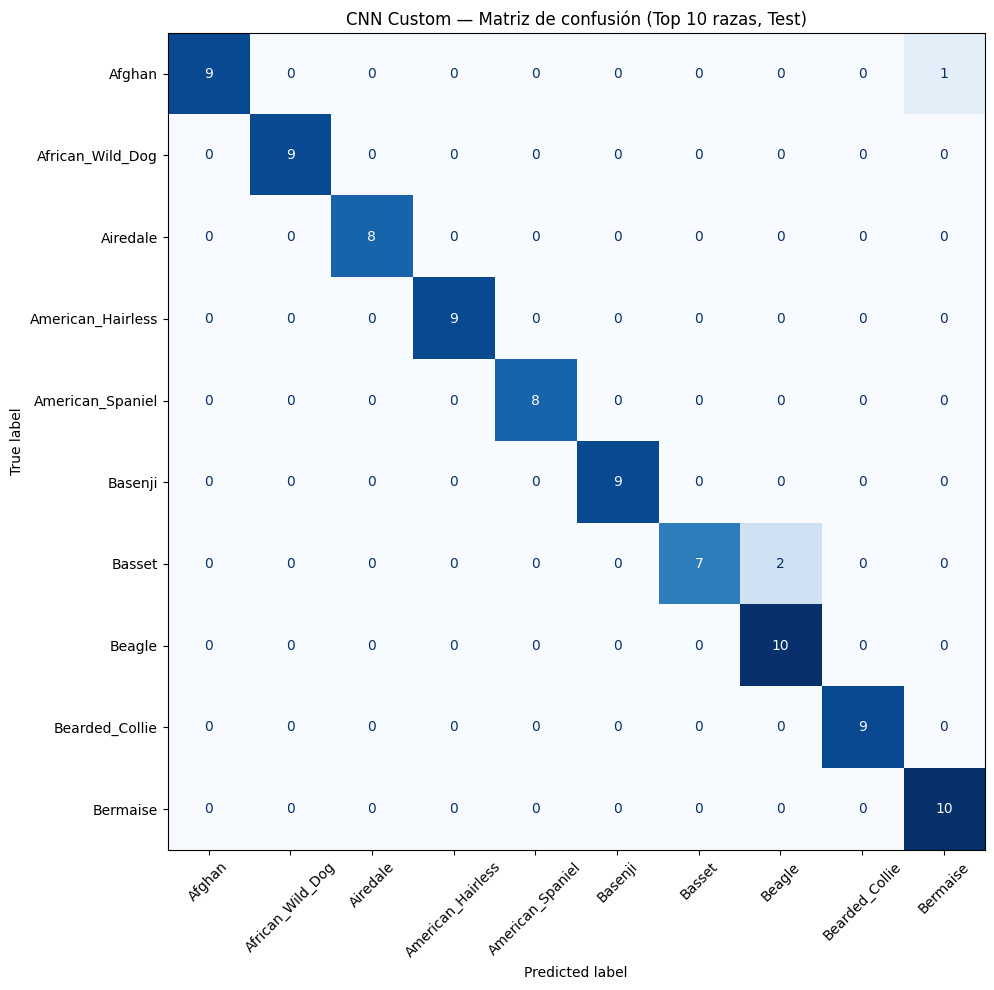

In [35]:
plot_confusion_matrix(y_true_cnn, y_pred_cnn, "CNN Custom")

La matriz de confusión muestra una mayor dispersión de errores respecto de la obtenida con ResNet-18, aunque la diagonal principal continúa siendo predominante.

Entre las principales confusiones identificadas se encuentran:

- Basset → Beagle: 2 imágenes clasificadas incorrectamente.
- Afghan → Bermaise: 1 imagen clasificada incorrectamente.

Estas confusiones pueden relacionarse con similitudes en determinadas características morfológicas de las razas, como las proporciones faciales, la estructura corporal y el pelaje.

En comparación con ResNet-18, la CNN Custom presenta una mayor cantidad de clasificaciones incorrectas y una menor capacidad para separar algunas categorías. Este comportamiento coincide con la diferencia observada en las métricas globales y evidencia las limitaciones de la arquitectura entrenada desde cero.

### 9.4 Pipeline visual completo (Test + OOD)

La siguiente visualización muestra nuevamente el flujo completo del sistema:

```text
Imagen → YOLO → Recorte → CNN Custom
```

Se utilizan exactamente los mismos ejemplos mostrados para ResNet-18, permitiendo observar cómo cambia la clasificación final cuando se reemplaza únicamente el modelo encargado de reconocer la raza.

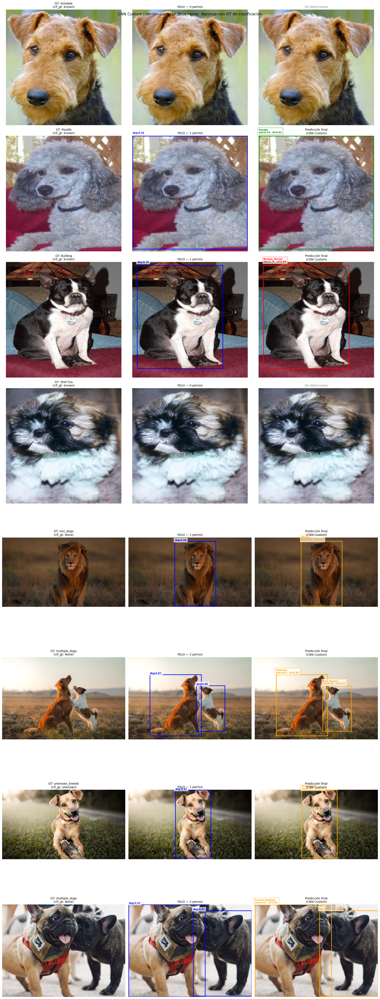

In [36]:
N_ROWS = N_TEST + N_OOD
fig, axes = plt.subplots(N_ROWS, 3, figsize=(18, 6 * N_ROWS))

for row, idx in enumerate(FIXED_TEST_INDICES):
    draw_pipeline_row(axes[row], X_test_paths[idx], y_test_labels[idx],
                      clf_gt="known", clf_model=modelo_cnn, model_name="CNN Custom")
    axes[row][0].set_ylabel("TEST", fontsize=11, fontweight="bold", labelpad=10)

for row, idx in enumerate(FIXED_OOD_INDICES):
    abs_row = N_TEST + row
    draw_pipeline_row(axes[abs_row], X_ood_paths[idx], y_ood_label[idx],
                      clf_gt=y_ood_clf[idx], clf_model=modelo_cnn, model_name="CNN Custom")
    axes[abs_row][0].set_ylabel("OOD", fontsize=11, fontweight="bold", labelpad=10)

plt.suptitle(
    "CNN Custom | Verde=correcto  Rojo=error  Naranja=sin GT de clasificación",
    fontsize=13
)
plt.tight_layout()
plt.show()

La comparación directa con la sección anterior permite observar diferencias en el comportamiento del pipeline al reemplazar ResNet-18 por CNN Custom, manteniendo constante la etapa de detección con YOLO.

Como las imágenes de entrada y las detecciones de YOLO son las mismas, las diferencias observadas en las predicciones finales corresponden principalmente al comportamiento del clasificador.

En las primeras cuatro filas pueden identificarse algunos casos donde el detector genera recortes válidos, pero la CNN Custom presenta dificultades para asignar correctamente la raza. En particular, la tercera fila muestra una clasificación incorrecta, marcada en rojo.

Por otra parte, las filas donde no aparecen cajas en la salida final requieren distinguir entre posibles fallos de detección y detecciones que no superaron los criterios de confianza establecidos. En estos casos, no es posible atribuir directamente el resultado al clasificador.

Los ejemplos OOD permiten analizar el comportamiento del sistema ante imágenes que no pertenecen al conjunto de razas utilizado durante el entrenamiento. También se incluyen escenas con múltiples perros y situaciones de oclusión, que representan condiciones más complejas que las imágenes individuales del conjunto Test.

En conjunto, esta visualización permite observar que, incluso cuando YOLO proporciona recortes adecuados, la CNN Custom presenta mayores dificultades para reconocer correctamente las razas. Esto evidencia la influencia de la capacidad de representación del clasificador sobre el rendimiento final del pipeline.

### 9.5 Casos específicos requeridos por la consigna — CNN Custom

Al igual que para ResNet-18, se verifica el comportamiento del pipeline sobre los tres escenarios funcionales solicitados por la consigna:

1. Un único perro.
2. Múltiples perros.
3. Ausencia de perros.

Esta evaluación permite comprobar que el flujo completo continúa funcionando correctamente independientemente del clasificador utilizado.

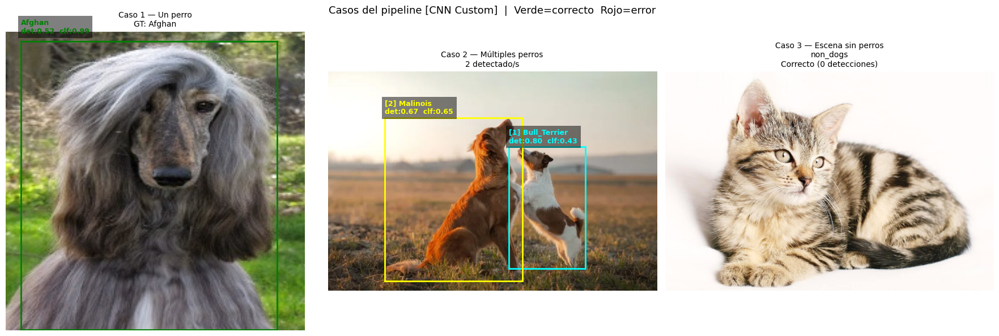

In [37]:
plot_casos_pipeline(modelo_cnn, "CNN Custom",
                    _img_single, _true_single,
                    _img_multi, _img_non_dog, _label_non_dog)

En el escenario con un único perro, YOLO localiza correctamente al animal y la CNN Custom identifica su raza como Afghan, coincidiendo con la etiqueta real. Este resultado demuestra que, en determinadas condiciones, la arquitectura personalizada también puede producir clasificaciones correctas y con elevada confianza.

En el escenario con múltiples perros, YOLO identifica correctamente dos individuos presentes en la escena. Posteriormente, la CNN procesa cada recorte de manera independiente y genera las predicciones Malinois y Bull Terrier. Este caso permite observar la capacidad del sistema para procesar múltiples detecciones simultáneamente, aunque la corrección de cada clasificación debe determinarse comparando las predicciones con las etiquetas reales de ambos animales.

Finalmente, en la imagen sin perros, el detector no genera falsas detecciones sobre el gato presente en la escena. En consecuencia, la etapa de clasificación no se ejecuta y el sistema produce el comportamiento esperado.

Estos ejemplos permiten verificar el funcionamiento de la lógica general del pipeline en los tres escenarios requeridos por la consigna. Sin embargo, también muestran que la correcta detección de los animales no garantiza necesariamente una clasificación acertada, ya que esta última depende de la capacidad del modelo para reconocer las características visuales de cada raza.

## 10. Comparación ResNet-18 vs CNN Custom — Pipeline completo con YOLO

Hasta este punto se evaluaron los clasificadores de manera aislada y posteriormente se analizaron ejemplos cualitativos del pipeline completo.

En esta sección se comparan formalmente ambas configuraciones integradas dentro del flujo completo:

```text
Imagen → YOLO → Recorte → Clasificador
```

La evaluación se realiza sobre dos conjuntos con características significativamente diferentes:

* **Test**: imágenes ya recortadas y centradas sobre el perro.
* **OOD known_breeds**: imágenes obtenidas de internet con contexto natural alrededor del animal.

La hipótesis central es que YOLO fue entrenado sobre COCO utilizando escenas naturales donde los objetos aparecen rodeados de contexto visual. Como consecuencia, se espera que el detector funcione mejor sobre imágenes OOD que sobre las imágenes del conjunto Test, que ya se encuentran recortadas.

Una predicción se considera correcta únicamente cuando ambas etapas funcionan correctamente: YOLO debe detectar al perro y el clasificador debe asignar la raza adecuada. Si el detector no produce ninguna detección, la predicción se registra como `__no_detection__`, penalizando explícitamente el error dentro de las métricas finales.

### 10.1 Tabla de métricas globales

Se evalúan ambas configuraciones del pipeline sobre los conjuntos Test y OOD known_breeds.

A diferencia de las métricas mostradas anteriormente para los clasificadores aislados, estos resultados incorporan simultáneamente los errores producidos por la etapa de detección y por la etapa de clasificación.

Por este motivo, los valores obtenidos representan el comportamiento real esperado en un entorno de producción.

In [38]:
# Evaluación sobre Test
print("Evaluando sobre Test...")
y_true_r_test, y_pred_r_test, y_true_c_test, y_pred_c_test, n_nd_test = \
    evaluar_pipeline(X_test_paths, y_test_labels)

# Evaluación sobre OOD known_breeds
ood_known_paths  = [p for p, c in zip(X_ood_paths, y_ood_clf) if c == "known"]
ood_known_labels = [l for l, c in zip(y_ood_label, y_ood_clf) if c == "known"]

print("Evaluando sobre OOD known_breeds...")
y_true_r_ood, y_pred_r_ood, y_true_c_ood, y_pred_c_ood, n_nd_ood = \
    evaluar_pipeline(ood_known_paths, ood_known_labels)

# Tabla comparativa
m_r_test = metricas(y_true_r_test, y_pred_r_test)
m_c_test = metricas(y_true_c_test, y_pred_c_test)
m_r_ood  = metricas(y_true_r_ood,  y_pred_r_ood)
m_c_ood  = metricas(y_true_c_ood,  y_pred_c_ood)

print(f"\nTest        — total: {len(X_test_paths):>4}  |  sin detección YOLO: {n_nd_test} ({100*n_nd_test/len(X_test_paths):.1f}%)")
print(f"OOD known   — total: {len(ood_known_paths):>4}  |  sin detección YOLO: {n_nd_ood} ({100*n_nd_ood/len(ood_known_paths):.1f}%)\n")

tabla = [
    ["Accuracy",
     f"{m_r_test['acc']:.4f}", f"{m_c_test['acc']:.4f}",
     f"{m_r_ood['acc']:.4f}",  f"{m_c_ood['acc']:.4f}"],
    ["Precision (macro)",
     f"{m_r_test['prec']:.4f}", f"{m_c_test['prec']:.4f}",
     f"{m_r_ood['prec']:.4f}",  f"{m_c_ood['prec']:.4f}"],
    ["Recall (macro)",
     f"{m_r_test['rec']:.4f}", f"{m_c_test['rec']:.4f}",
     f"{m_r_ood['rec']:.4f}",  f"{m_c_ood['rec']:.4f}"],
    ["F1-score (macro)",
     f"{m_r_test['f1']:.4f}", f"{m_c_test['f1']:.4f}",
     f"{m_r_ood['f1']:.4f}",  f"{m_c_ood['f1']:.4f}"],
]

headers = ["Métrica", "ResNet-18\n(Test)", "CNN Custom\n(Test)", "ResNet-18\n(OOD known)", "CNN Custom\n(OOD known)"]
print(tabulate(tabla, headers=headers, tablefmt="github"))

Evaluando sobre Test...
Evaluando sobre OOD known_breeds...

Test        — total:  700  |  sin detección YOLO: 279 (39.9%)
OOD known   — total:   16  |  sin detección YOLO: 2 (12.5%)

| Métrica           |   ResNet-18 |   CNN Custom |     ResNet-18 |    CNN Custom |
|                   |      (Test) |       (Test) |   (OOD known) |   (OOD known) |
|-------------------|-------------|--------------|---------------|---------------|
| Accuracy          |      0.58   |       0.4771 |        0.6875 |        0.5    |
| Precision (macro) |      0.9405 |       0.773  |        0.4545 |        0.4167 |
| Recall (macro)    |      0.5718 |       0.4704 |        0.4273 |        0.3667 |
| F1-score (macro)  |      0.6755 |       0.5566 |        0.4385 |        0.381  |


Los resultados muestran una diferencia importante entre las métricas obtenidas por los clasificadores aislados y las observadas en el pipeline completo.

El dato más relevante es la cantidad de imágenes donde YOLO no logra detectar ningún perro:

Test: 279 imágenes sin detección (39.9%).

OOD known_breeds: 2 imágenes sin detección (12.5%).

Esta diferencia resulta especialmente significativa porque el conjunto Test contiene imágenes ya recortadas y centradas sobre el perro, mientras que las imágenes OOD conservan el contexto natural presente en escenas reales.

Los resultados respaldan la hipótesis planteada inicialmente: YOLO fue preentrenado sobre COCO utilizando escenas naturales y, en consecuencia, presenta mayores dificultades cuando recibe imágenes excesivamente recortadas, como ocurre con una parte importante del conjunto Test. No obstante, debido al tamaño reducido del conjunto OOD (16 imágenes), esta tendencia debe interpretarse con cierta cautela.

Esto explica por qué ResNet-18 pasa de una accuracy del 97% cuando se evalúa de forma aislada a aproximadamente 58% cuando forma parte del pipeline completo. Una parte importante de esa degradación está relacionada con los fallos de detección introducidos por YOLO, que impiden que el clasificador procese numerosas imágenes.

Por otra parte, la diferencia entre ResNet-18 y CNN Custom continúa siendo evidente en ambos conjuntos. En Test, ResNet-18 alcanza un F1-score de 0.6755 frente a 0.5566 de CNN Custom, mientras que en OOD obtiene 0.4385 frente a 0.3810. Esto confirma la ventaja de las representaciones aprendidas mediante transferencia de aprendizaje, incluso cuando ambos modelos se integran dentro del mismo pipeline.

### 10.2 Comparación visual — gráfico de barras

Para facilitar la comparación entre configuraciones se representan gráficamente las cuatro métricas principales obtenidas en la evaluación del pipeline completo.

La visualización permite comparar simultáneamente:

* ResNet-18 sobre Test.
* CNN Custom sobre Test.
* ResNet-18 sobre OOD known_breeds.
* CNN Custom sobre OOD known_breeds.

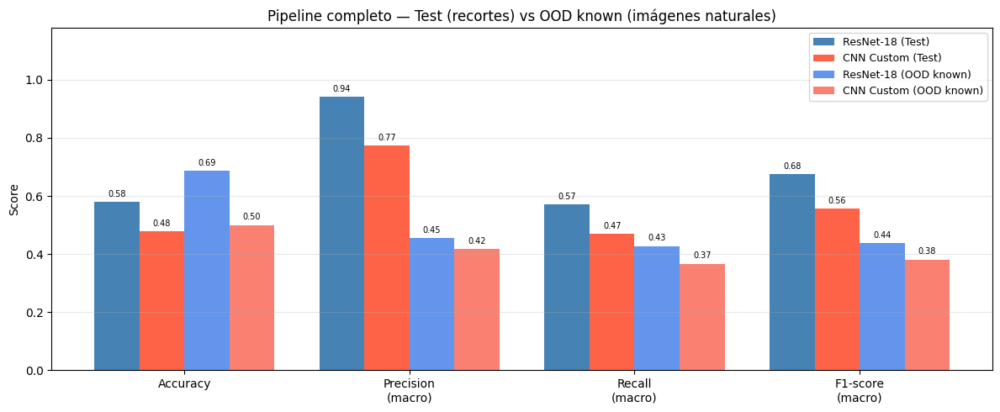

In [41]:
metric_names = ["Accuracy", "Precision\n(macro)", "Recall\n(macro)", "F1-score\n(macro)"]

vals = {
    "ResNet-18 (Test)":      [m_r_test["acc"], m_r_test["prec"], m_r_test["rec"], m_r_test["f1"]],
    "CNN Custom (Test)":     [m_c_test["acc"], m_c_test["prec"], m_c_test["rec"], m_c_test["f1"]],
    "ResNet-18 (OOD known)": [m_r_ood["acc"],  m_r_ood["prec"],  m_r_ood["rec"],  m_r_ood["f1"]],
    "CNN Custom (OOD known)":[m_c_ood["acc"],  m_c_ood["prec"],  m_c_ood["rec"],  m_c_ood["f1"]],
}
colors = ["steelblue", "tomato", "cornflowerblue", "salmon"]

x     = np.arange(len(metric_names))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 5))
for i, (label, vals_list) in enumerate(vals.items()):
    bars = ax.bar(x + (i - 1.5) * width, vals_list, width, label=label, color=colors[i])
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.18)
ax.set_ylabel("Score")
ax.set_title("Pipeline completo — Test (recortes) vs OOD known (imágenes naturales)")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El gráfico confirma visualmente las conclusiones obtenidas a partir de la tabla de métricas.

En primer lugar, ResNet-18 supera a CNN Custom en todas las métricas y escenarios evaluados, reflejando la ventaja proporcionada por el aprendizaje por transferencia.

En segundo lugar, se observa que el comportamiento del pipeline depende fuertemente del conjunto utilizado. La cantidad de imágenes sin detección de YOLO afecta directamente la accuracy y el recall globales, ya que estos casos se contabilizan como predicciones incorrectas.

Esta diferencia permite identificar que el rendimiento final no depende únicamente de la capacidad del clasificador, sino también de la capacidad del detector para localizar correctamente a los perros en las imágenes de entrada.

En conjunto, la visualización refuerza la conclusión de que YOLO constituye el principal cuello de botella del sistema sobre el conjunto Test, mientras que la elección del clasificador continúa teniendo un impacto significativo sobre la calidad de las predicciones.

### 10.3 Comparación lado a lado sobre las mismas imágenes

Las métricas agregadas permiten cuantificar el rendimiento global, pero no muestran cómo se comportan ambos clasificadores frente a ejemplos concretos.

Para complementar el análisis se visualizan exactamente las mismas imágenes procesadas por ambos pipelines, permitiendo comparar directamente las predicciones generadas por ResNet-18 y CNN Custom.

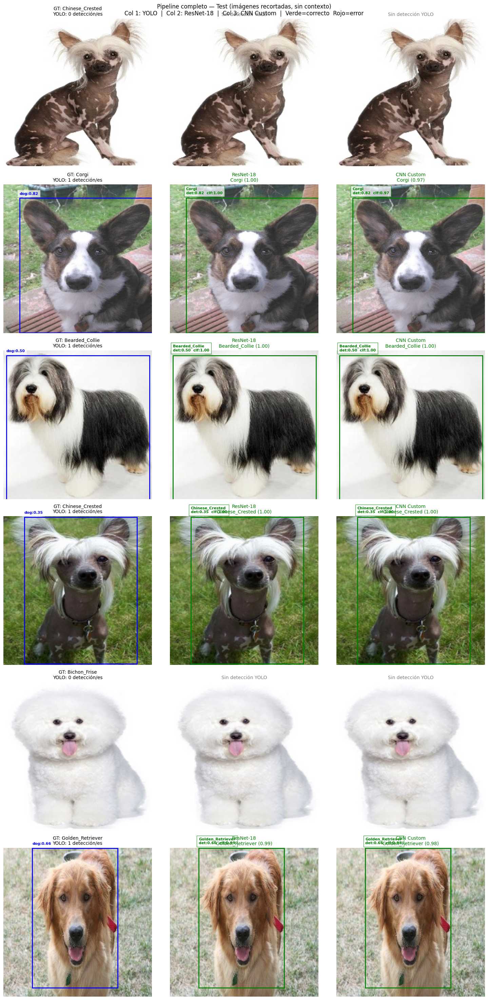

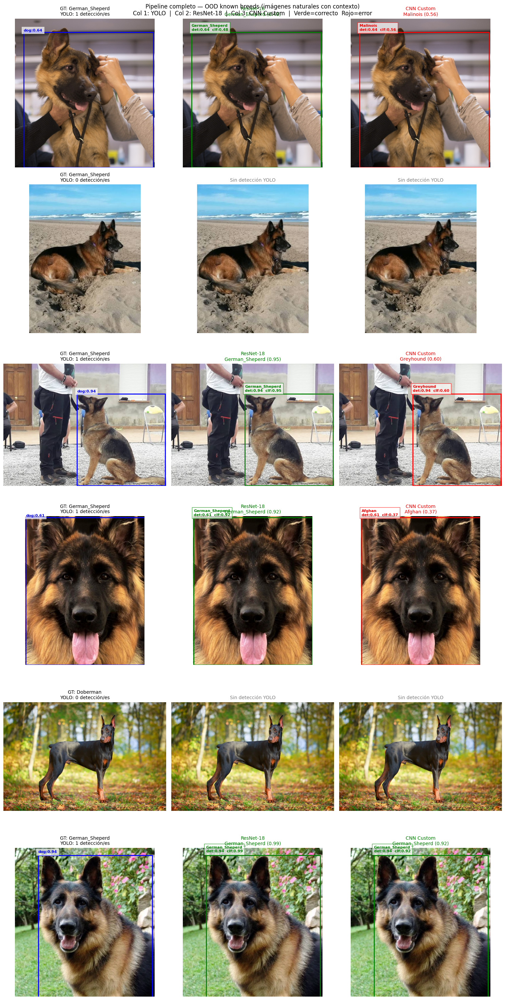

In [40]:
plot_comparacion_pipeline(
    X_test_paths, y_test_labels,
    titulo="Pipeline completo — Test (imágenes recortadas, sin contexto)",
)

plot_comparacion_pipeline(
    ood_known_paths, ood_known_labels,
    titulo="Pipeline completo — OOD known breeds (imágenes naturales con contexto)",
)

La comparación visual permite identificar claramente dos fuentes distintas de error dentro del sistema.

Por un lado, existen imágenes donde YOLO no genera ninguna detección a pesar de que el perro está presente. En estos casos, ambos clasificadores fallan automáticamente, ya que nunca reciben un recorte para procesar. Este comportamiento evidencia el impacto directo de la etapa de detección sobre el rendimiento global del pipeline.

Por otro lado, cuando la detección se produce correctamente, pueden observarse diferencias entre ambos clasificadores. ResNet-18 logra identificar correctamente numerosas razas para las cuales CNN Custom produce predicciones incorrectas, reflejando la superioridad observada previamente en las métricas del clasificador aislado.

También aparecen ejemplos donde ambos modelos fallan o donde los recortes generados por YOLO dificultan la clasificación posterior.

En conjunto, estas observaciones cualitativas son consistentes con los resultados cuantitativos y permiten comprender cómo los errores de cada etapa se combinan para determinar el rendimiento final del sistema.

## 11. Conclusiones

En esta etapa se desarrolló y evaluó un pipeline completo de detección y clasificación de razas de perros, integrando un detector basado en YOLOv8n con dos clasificadores entrenados durante la Etapa 2: una ResNet-18 fine-tuned mediante transferencia de aprendizaje y una CNN Custom entrenada desde cero.

Los resultados obtenidos muestran que **ResNet-18 fue el modelo de clasificación más efectivo**, alcanzando métricas significativamente superiores a las de CNN Custom tanto en la evaluación aislada como dentro del pipeline completo. Este comportamiento era esperable debido al uso de pesos preentrenados sobre ImageNet, que proporcionan representaciones visuales robustas y facilitan la generalización incluso con cantidades moderadas de datos de entrenamiento.

Por su parte, la **CNN Custom** permitió establecer una arquitectura de referencia (*baseline*) para evaluar experimentalmente las ventajas del aprendizaje por transferencia. Aunque su rendimiento fue considerablemente inferior, permitió comprobar la importancia de disponer de representaciones visuales previamente aprendidas para resolver problemas de clasificación con numerosas clases.

Respecto a la etapa de detección, **YOLOv8n demostró ser capaz de localizar perros en diferentes escenarios sin necesidad de reentrenamiento**, aprovechando la clase *dog* incluida en el dataset COCO. Sin embargo, su desempeño presentó diferencias importantes dependiendo de las características de las imágenes de entrada.

El análisis del pipeline completo permitió identificar que **la etapa de detección constituye una de las principales fuentes de error del sistema**, especialmente sobre el conjunto Test. En este conjunto, YOLO no produjo ninguna detección válida en 279 de las 700 imágenes evaluadas (39.9%). Como consecuencia, incluso cuando ResNet-18 conserva una elevada capacidad de clasificación sobre los recortes detectados, la accuracy global desciende hasta aproximadamente el 58%.

La comparación entre Test y OOD known_breeds aporta evidencia para explicar este comportamiento. Las imágenes de Test corresponden a recortes centrados sobre el perro, mientras que las imágenes OOD conservan el contexto natural de la escena. En este experimento, YOLO presentó una menor proporción de fallos de detección sobre las imágenes OOD, pasando de un 39.9% en Test a un 12.5%. No obstante, debido al tamaño reducido del conjunto OOD, estos resultados deben interpretarse como una tendencia observada y no como una conclusión general sobre el comportamiento del detector.

Finalmente, se identificó una limitación importante del enfoque utilizado: los clasificadores fueron entrenados utilizando las imágenes originales del dataset, mientras que durante la inferencia reciben recortes generados por YOLO. Esta diferencia entre las condiciones de entrenamiento e inferencia puede introducir una discrepancia en las características visuales de entrada. En un sistema productivo real, sería recomendable entrenar los modelos de clasificación utilizando recortes obtenidos mediante el propio detector, reduciendo dicha discrepancia y potencialmente mejorando el rendimiento global del pipeline.

En conclusión, el sistema desarrollado permitió integrar satisfactoriamente las etapas de detección y clasificación, cumpliendo con los escenarios funcionales establecidos en la consigna. Asimismo, los experimentos realizados permitieron identificar las fortalezas y limitaciones de cada componente, demostrando la superioridad de ResNet-18 como clasificador y señalando oportunidades concretas de mejora para la etapa de detección.